<a href="https://colab.research.google.com/github/Unknownboykim/AI-Ecommerce-Analyst/blob/master/S04_Classes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

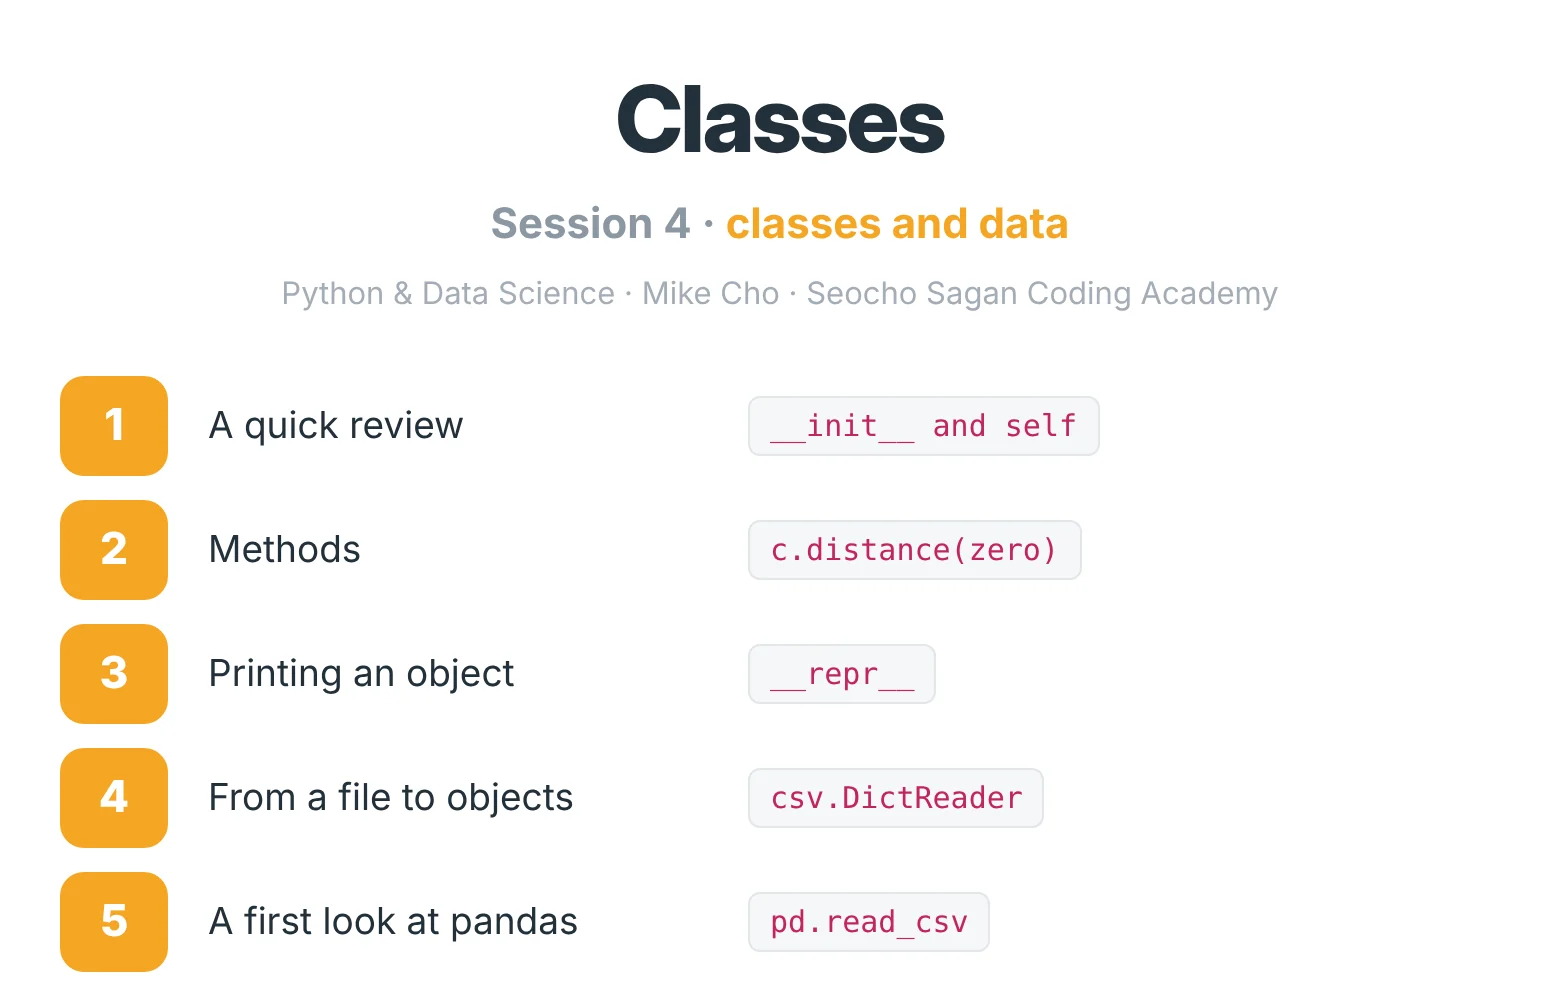

In [1]:
#@title Setup: press ▶ once and move on { display-mode: "form" }
import contextlib, copy, io, signal, time, traceback
import html as _h
from IPython.display import HTML, display

_T0 = time.time()
_LOG = {}
_TOUCH = [_T0]
_TONES = {"ok": ("#2e7d4f", "#f0f7f0", "#b5d9b9"), "no": ("#c96a04", "#fff3e4", "#f3c184"),
          "err": ("#c0392b", "#fdeeee", "#f0b5b5"), "idle": ("#5d6b78", "#f5f6f8", "#d5dae0")}
_FONT = "font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Inter,sans-serif;"
_MONO = "font-family:'SF Mono',Consolas,Menlo,'DejaVu Sans Mono',monospace;"


def _card(tone, title, lines=()):
    ink, fill, edge = _TONES[tone]
    body = "".join(f"<div style='margin-top:7px'>{x}</div>" for x in lines)
    return (
        f"<div style=\"{_FONT}background:{fill};border:2px solid {edge};border-radius:14px;"
        f"padding:13px 18px 14px;margin:6px 0 14px 0;color:#22303a;font-size:15.5px;line-height:1.5;max-width:760px\">"
        f"<div style='font-weight:800;font-size:16.5px;color:{ink}'>{title}</div>{body}</div>"
    )


def _code(x):
    return (f"<code style=\"{_MONO}background:#ffffff;border:1px solid #e3e6ea;padding:1px 7px;border-radius:6px;"
            f"color:#c2255c;font-size:14px;white-space:pre-wrap\">{_h.escape(str(x))}</code>")


class _Timeout(Exception):
    pass


def _alarm(signum, frame):
    raise _Timeout()


def _call(func, args, seconds=2):
    out = io.StringIO()
    armed = False
    try:
        old = signal.signal(signal.SIGALRM, _alarm)
        signal.setitimer(signal.ITIMER_REAL, seconds)
        armed = True
    except Exception:
        pass
    try:
        with contextlib.redirect_stdout(out):
            value = func(*copy.deepcopy(args))
        return "ok", value, out.getvalue(), ""
    except _Timeout:
        return "timeout", None, out.getvalue(), ""
    except Exception as e:
        where = ""
        frames = traceback.extract_tb(e.__traceback__)
        if len(frames) > 1 and frames[-1].line:
            where = frames[-1].line.strip()
        return "error", f"{type(e).__name__}: {e}", out.getvalue(), where
    finally:
        if armed:
            signal.setitimer(signal.ITIMER_REAL, 0)
            signal.signal(signal.SIGALRM, old)


def _same(got, want, tol=0):
    if isinstance(want, bool) or isinstance(got, bool):
        return type(got) is type(want) and got == want
    if isinstance(want, (int, float)):
        return isinstance(got, (int, float)) and abs(got - want) <= tol + 1e-9
    if isinstance(want, (list, tuple)):
        return (type(got) is type(want) and len(got) == len(want)
                and all(_same(g, w, tol) for g, w in zip(got, want)))
    return got == want


def _begin(pid):
    return _LOG.setdefault(pid, {"tries": 0, "done": False, "start": _TOUCH[0], "secs": None, "score": None})


def _finish(pid, score=None):
    rec = _LOG[pid]
    if not rec["done"]:
        rec.update(done=True, secs=time.time() - rec["start"], score=score)


def _label(pid):
    p = SPEC[pid]
    return f"{pid} · {p['name']}"


def _norm(s):
    return " ".join(str(s).split()).replace(", ", ",")


def check_read(pid, *lines):
    p = SPEC[pid]
    out = io.StringIO()
    with contextlib.redirect_stdout(out):
        exec(p["snippet"], copy.deepcopy(ENV))
    actual = out.getvalue().rstrip("\n").split("\n")
    guess = [str(x).strip() for x in lines]
    if not all(guess[:len(actual)]) or len(guess) < len(actual):
        display(HTML(_card("idle", _label(pid), ["Fill in every box, then run this cell. Type <code>?</code> for a line you don't know."])))
        return
    rec = _begin(pid)
    rec["tries"] += 1
    rows, hits = "", 0
    for i, real in enumerate(actual):
        g = guess[i] if i < len(guess) else ""
        ok = _norm(g) == _norm(real)
        hits += ok
        mark = "<span style='color:#2e7d4f;font-weight:700'>✓</span>" if ok else "<span style='color:#c0392b;font-weight:700'>✗</span>"
        rows += (f"<tr><td style='text-align:left;padding:3px 14px 3px 0;color:#555555'>line {i + 1}</td>"
                 f"<td style='text-align:left;padding:3px 14px 3px 0'>{_code(g) if g else '<span style=\"color:#777777\">(empty)</span>'}</td>"
                 f"<td style='text-align:left;padding:3px 14px 3px 0'>{mark}</td>"
                 f"<td style='text-align:left;padding:3px 0'>{_code(real)}</td></tr>")
    table = ("<table style='border-collapse:collapse;font-size:14px;margin-top:4px'>"
             "<tr style='color:#555555;font-size:12px'><td style='text-align:left'></td><td style='text-align:left;padding-right:14px'>you said</td><td style='text-align:left'></td><td style='text-align:left'>it prints</td></tr>"
             f"{rows}</table>")
    _finish(pid, (hits, len(actual)))
    _TOUCH[0] = time.time()
    tone = "ok" if hits == len(actual) else "no"
    display(HTML(_card(tone, f"{_label(pid)} — {hits} of {len(actual)} lines", [table])))


def check(pid, obj=None):
    p = SPEC[pid]
    if "expect" in p:
        _check_value(pid, p, obj)
    else:
        _check_tests(pid, p, obj)
    _TOUCH[0] = time.time()


def _check_value(pid, p, obj):
    def _blank(x):
        if x is ...:
            return True
        if isinstance(x, (list, tuple)):
            return any(_blank(y) for y in x)
        if isinstance(x, dict):
            return any(_blank(y) for y in x.values())
        return False
    if obj is None or _blank(obj):
        display(HTML(_card("idle", _label(pid), ["Replace every <code>...</code> with your own code, then run this cell again."])))
        return
    rec = _begin(pid)
    rec["tries"] += 1
    want = p["expect"]
    if _same(obj, want, p.get("tol", 0)):
        _finish(pid)
        shown = repr(obj)
        display(HTML(_card("ok", f"✓ {_label(pid)}", [_code(shown) if len(shown) <= 70 else "That's right."])))
        return
    def _why(got, need):
        if isinstance(need, dict):
            if not isinstance(got, dict):
                return f"should be a dictionary, but its type is {type(got).__name__}."
            miss = [k for k in need if k not in got]
            extra = [k for k in got if k not in need]
            wrong = [k for k in need if k in got and not _same(got[k], need[k], p.get("tol", 0))]
            bits = []
            if miss:
                bits.append("is missing the key " + ", ".join(_code(repr(k)) for k in miss[:3]) + ("" if len(miss) <= 3 else " and more"))
            if extra:
                bits.append("has a key it shouldn't have: " + ", ".join(_code(repr(k)) for k in extra[:3]))
            if wrong:
                bits.append("has the wrong value for " + ", ".join(_code(repr(k)) for k in wrong[:3]))
            return "; ".join(bits) + "." if bits else "isn't the right value yet."
        if isinstance(need, set):
            if not isinstance(got, set):
                return f"should be a set, but its type is {type(got).__name__}."
            return "has the wrong items."
        if isinstance(need, list) and not isinstance(got, list):
            return f"should be a list, but its type is {type(got).__name__}."
        if isinstance(need, list) and len(got) != len(need):
            return f"has {len(got)} items. It should have {len(need)}."
        if not isinstance(need, list):
            return "isn't the right value yet."
        return "has the right number of items, but the values aren't right yet."
    names = p.get("names")
    if names and isinstance(obj, tuple) and len(obj) == len(names):
        lines = []
        for name, got, need in zip(names, obj, want):
            if _same(got, need, p.get("tol", 0)):
                lines.append(f"{_code(name)} is right.")
            else:
                lines.append(f"{_code(name)} {_why(got, need)}<br>It is now {_code(repr(got))}")
    else:
        lines = [f"You have {_code(repr(obj))}", "It " + _why(obj, want)]
    display(HTML(_card("no", f"{_label(pid)} — not yet", lines)))


def _has_blanks(func):
    try:
        import ast, inspect, textwrap
        tree = ast.parse(textwrap.dedent(inspect.getsource(func)))
        return any(isinstance(n, ast.Constant) and n.value is ... for n in ast.walk(tree))
    except Exception:
        return False


def _check_tests(pid, p, func):
    if not callable(func):
        display(HTML(_card("idle", _label(pid), ["Pass your function to <code>check</code>."])))
        return
    if _has_blanks(func):
        display(HTML(_card("idle", _label(pid), ["Replace every <code>...</code> with your own code, then run this cell again."])))
        return
    if p.get("banned"):
        try:
            import inspect, textwrap
            _src = textwrap.dedent(inspect.getsource(func))
            import ast as _ast
            _tree = _ast.parse(_src)
            _loops = {"for ": (_ast.For, _ast.comprehension), "while ": (_ast.While,)}
            _code_only = "\n".join(l.split("#")[0] for l in _src.splitlines())
            _calls = {n.func.id for n in _ast.walk(_tree) if isinstance(n, _ast.Call) and isinstance(n.func, _ast.Name)}
            def _hit(b):
                if b in _loops:
                    return any(isinstance(n, _loops[b]) for n in _ast.walk(_tree))
                if b.endswith("(") and b[:-1].isidentifier():
                    return b[:-1] in _calls
                return b in _code_only
            _used = [b.rstrip("(").strip() for b in p["banned"] if _hit(b)]
        except Exception:
            _used = []
        if _used:
            _msg = p.get("banned_msg", "This problem asks you to write the loop yourself. Your code uses {used}.")
            display(HTML(_card("no", f"{_label(pid)} — not yet", [_msg.replace("{used}", ", ".join(_code(u) for u in _used))])))
            return
    rec = _begin(pid)
    rec["tries"] += 1
    tests = p["tests"]
    if p.get("returns_fn"):
        import inspect as _insp
        _n = len(_insp.signature(func).parameters)
        _fns0 = {k: eval(v) for k, v in p.get("fns", {}).items()}
        _a0 = tuple(_fns0[a[1:]] if isinstance(a, str) and a.startswith("@") and a[1:] in _fns0 else a for a in tests[0][0][:_n])
        _shown0 = f"{func.__name__}(" + ", ".join(a[1:] if isinstance(a, str) and a.startswith("@") else repr(a) for a in tests[0][0][:_n]) + ")"
        _kind0, _got0, _pr0, _wh0 = _call(func, _a0)
        if _kind0 == "ok" and not callable(_got0):
            display(HTML(_card("no", f"{_label(pid)} — not yet",
                               [f"{_code(_shown0)} returned {_code(repr(_got0))}.", "It should return a <b>function</b>, like <code>make_prod</code> returns <code>g</code>."])))
            return
    for n, t in enumerate(tests):
        args, want = t[0], t[1]
        opt = t[2] if len(t) > 2 else {}
        _fns = {k: eval(v) for k, v in p.get("fns", {}).items()}
        def _sub(a):
            if isinstance(a, str) and a.startswith("@") and a[1:] in _fns:
                return _fns[a[1:]]
            if isinstance(a, list):
                return [_sub(x) for x in a]
            return a
        _args = tuple(_sub(a) for a in args)
        _shown_args = ", ".join(a[1:] if isinstance(a, str) and a.startswith("@") and a[1:] in _fns else repr(a) for a in args)
        shown = opt.get("label") or f"{func.__name__}({_shown_args})"
        _run = eval(p["wrap"])(func) if p.get("wrap") else func
        kind, got, printed, where = _call(_run, _args)
        passed_so_far = f"<span style='color:#555555'>Test {n + 1} of {len(tests)} failed. Fix this one first.</span>"
        if kind == "timeout":
            display(HTML(_card("err", f"{_label(pid)} — still running after 2 seconds",
                               [f"{_code(shown)} never finished. That usually means a loop that never ends.", passed_so_far])))
            return
        if kind == "error":
            lines = [f"{_code(shown)} stopped with an error:", _code(got)]
            if where:
                lines.append(f"on this line: {_code(where)}")
            lines.append(passed_so_far)
            display(HTML(_card("err", f"{_label(pid)} — error", lines)))
            return
        if not _same(got, want, opt.get("tol", p.get("tol", 0))):
            lines = [f"{_code(shown)}", f"returned {_code(repr(got))}", f"expected {_code(repr(want))}"]
            if got is None and printed.strip():
                lines.append("Your function <b>printed</b> something but returned nothing. Use <code>return</code>.")
            elif got is None:
                lines.append("Nothing is returned yet.")
            lines.append(passed_so_far)
            display(HTML(_card("no", f"{_label(pid)} — not yet", lines)))
            return
    _finish(pid)
    tries = "first run" if rec["tries"] == 1 else f"run {rec['tries']}"
    display(HTML(_card("ok", f"✓ {_label(pid)}", [f"All {len(tests)} tests passed <span style='color:#555555'>· {tries}</span>"])))


def mark(pid, ok):
    rec = _begin(pid)
    if ok:
        rec["tries"] = max(rec["tries"], 1)
        _finish(pid)
        display(HTML(_card("ok", f"✓ {_label(pid)}", ["Marked as matching the sample."])))
    else:
        display(HTML(_card("idle", _label(pid), ["Check the box once your output matches the sample, then run this cell."])))
    _TOUCH[0] = time.time()


# ----------------------------------------------------------------------------- about the student
_ABOUT = {"rate": {}, "goals": {}, "exit": {}}
_BLANK = ("", "(choose)")
SCALE = ["new to me", "seen it, rarely used it", "can write it with a reference open", "can write it from memory", "could teach it"]
TOPICS = {"strings": ("Strings", "today"), "loops": ("for and while loops", "today"), "lists": ("Lists", "Session 2"),
          "tuples_dicts_sets": ("Tuples, dictionaries, sets", "Session 3"), "functions": ("Functions", "Session 4"),
          "classes": ("Classes", "Session 5"), "pandas_tables": ("pandas", "Session 6"), "numpy_arrays": ("NumPy", "Session 7")}
GOAL_Q = {"want_most": ("1 · What you want", True), "matters_most": ("2 · Matters most", True), "project_plan": ("3 · Project plan", True)}
EXIT_Q = {"pace_today": ("Pace", True), "difficulty_today": ("Difficulty", True), "more_of": ("More of", False), "less_of": ("Less of", False)}


def _level(v):
    s = str(v).strip()
    return int(s[0]) if s and s[0] in "12345" else None


def _bar(n):
    cells = "".join(f"<span style='display:inline-block;width:20px;height:10px;border-radius:3px;margin-right:3px;"
                    f"background:{'#2c5ea8' if i < n else '#e3e6ea'}'></span>" for i in range(5))
    return f"<span style='white-space:nowrap'>{cells}</span>"


def _rate_table(vals, when):
    rows = ""
    for key, n in vals.items():
        label, session = TOPICS[key]
        rows += (f"<tr><td style='text-align:left;padding:4px 16px 4px 0;font-weight:600'>{label}</td>"
                 f"<td style='text-align:left;padding:4px 12px 4px 0'>{_bar(n)}</td>"
                 f"<td style='text-align:left;padding:4px 16px 4px 0;color:#333333'>{n} · {SCALE[n - 1]}</td>"
                 + (f"<td style='text-align:left;padding:4px 0;color:#777777'>{session}</td>" if when else "") + "</tr>")
    return f"<table style='border-collapse:collapse;font-size:14px;margin-top:2px'>{rows}</table>"


def _answer_table(questions, answers):
    rows = ""
    for key, (label, _) in questions.items():
        text = answers.get(key, "")
        if text in _BLANK:
            continue
        rows += (f"<tr><td style='text-align:left;vertical-align:top;padding:4px 16px 4px 0;color:#555555;white-space:nowrap'>{label}</td>"
                 f"<td style='text-align:left;padding:4px 0;font-weight:600'>{_h.escape(text)}</td></tr>")
    return f"<table style='border-collapse:collapse;font-size:14px;margin-top:2px'>{rows}</table>"


def about_you(**ratings):
    vals = {k: _level(v) for k, v in ratings.items()}
    still = [TOPICS[k][0] for k, v in vals.items() if v is None]
    if still:
        display(HTML(_card("idle", "Pick a number on every line, then run this cell again.", ["Still open: " + ", ".join(still)])))
        return
    _ABOUT["rate"] = vals
    display(HTML(_card("ok", "✓ Saved", [_rate_table(vals, False)])))


def _form(slot, questions, answers, title):
    clean = {k: " ".join(str(v).split()) for k, v in answers.items()}
    still = [label for k, (label, need) in questions.items() if need and clean.get(k, "") in _BLANK]
    if still:
        display(HTML(_card("idle", "Answer every question, then run this cell again.", ["Still open: " + ", ".join(still)])))
        return
    _ABOUT[slot] = clean
    display(HTML(_card("ok", title, [_answer_table(questions, clean)])))


def where_headed(**answers):
    _form("goals", GOAL_Q, answers, "✓ Saved")


def before_you_go(**answers):
    _form("exit", EXIT_Q, answers, "✓ Thanks. That's it for today.")


def _snapshot(tally):
    tones = {"read": ("#7b3fc4", "#f5effc", "#d3bdf0"), "fix": ("#c96a04", "#fff3e4", "#f3c184"), "write": ("#2e7d4f", "#f0f7f0", "#b5d9b9")}
    stats = ""
    for kind, (ink, fill, edge) in tones.items():
        got, total = tally.get(kind, (0, 0))
        stats += (f"<div style='flex:1;background:{fill};border:2px solid {edge};border-radius:12px;padding:10px 14px'>"
                  f"<div style='font-size:11px;letter-spacing:.08em;font-weight:800;color:{ink}'>{KINDS[kind].upper()}</div>"
                  f"<div style='font-size:24px;font-weight:800;color:#22303a;margin-top:2px'>{got}<span style='font-size:15px;color:#777777;font-weight:600'> of {total}</span></div></div>")
    head = lambda t: f"<div style='margin-top:16px;font-size:11px;letter-spacing:.08em;color:#555555;font-weight:700'>{t}</div>"
    parts = [f"<div style='display:flex;gap:10px;margin-top:10px'>{stats}</div>"]
    if _ABOUT["rate"]:
        parts.append(head("HOW YOU RATED YOURSELF") + _rate_table(_ABOUT["rate"], True))
    if _ABOUT["goals"]:
        parts.append(head("WHERE YOU'RE HEADED") + _answer_table(GOAL_Q, _ABOUT["goals"]))
    if not (_ABOUT["rate"] and _ABOUT["goals"]):
        parts.append("<div style='margin-top:12px;color:#c96a04;font-weight:600'>The two forms at the top aren't filled in yet. Fill them in and run them, then run this cell again.</div>")
    parts.append("<div style='margin-top:14px;font-size:13px;color:#555555'>I'll plan the next sessions from this page, with more time where the numbers are low and less where they're high.</div>")
    display(HTML(
        f"<div style=\"{_FONT}background:#ffffff;border:2px solid #b7cdea;border-radius:14px;padding:16px 20px;"
        f"color:#22303a;font-size:15px;max-width:760px;margin:6px 0 14px 0\">"
        f"<div style='font-size:18px;font-weight:800;color:#2c5ea8'>Your snapshot</div>{''.join(parts)}</div>"
    ))


def show_results():
    chip = lambda text, color: f"<span style='color:{color};font-weight:700;white-space:nowrap'>{text}</span>"
    rows, tally, last_kind = "", {}, None
    simple = globals().get("RESULTS_SIMPLE")
    for pid, p in SPEC.items():
        rec = _LOG.get(pid)
        kind = p["kind"]
        got, total = tally.get(kind, (0, 0))
        if rec and rec["done"]:
            if rec["score"]:
                k, n = rec["score"]
                status = chip(f"{k} of {n}", "#2e7d4f" if k == n else "#c96a04")
                got += k == n
            else:
                status = chip("passed", "#2e7d4f")
                got += 1
        elif rec and rec["tries"]:
            status = chip("not yet", "#c96a04")
        else:
            status = chip("not started", "#777777")
        if not p.get("bonus"):
            tally[kind] = (got, total + 1)
        secs = rec["secs"] if rec and rec["secs"] is not None else None
        clock = f"{int(secs // 60)}:{int(secs % 60):02d}" if secs is not None else ""
        tries = rec["tries"] if rec and rec["tries"] else ""
        if kind != last_kind:
            rows += (f"<tr><td colspan='{4 if simple else 6}' style='text-align:left;padding:14px 0 4px 0;font-size:11px;letter-spacing:.08em;"
                     f"color:#555555;font-weight:700'>{KINDS[kind].upper()}</td></tr>")
            last_kind = kind
        rows += ("<tr style='border-top:1px solid #cccccc'>"
                 f"<td style='text-align:left;padding:7px 12px 7px 0;color:#555555'>{pid}</td>"
                 f"<td style='text-align:left;padding:7px 16px 7px 0;font-weight:600'>{_h.escape(p['name'])}</td>"
                 f"<td style='text-align:left;padding:7px 16px 7px 0;color:#333333'>{_h.escape(p['topic'])}</td>"
                 f"<td style='text-align:left;padding:7px 16px 7px 0'>{status}</td>"
                 + ("" if simple else f"<td style='text-align:left;padding:7px 16px 7px 0;color:#333333;text-align:right'>{tries}</td>"
                                      f"<td style='text-align:left;padding:7px 0;color:#333333;text-align:right'>{clock}</td>") + "</tr>")
    summary = " &nbsp;·&nbsp; ".join(f"<b>{KINDS[k]}</b> {g} / {t}" for k, (g, t) in tally.items())
    head = ("<tr style='font-size:12px;color:#555555'><td style='text-align:left'></td><td style='text-align:left'></td><td style='text-align:left'>" + ("topic" if any(q.get("topic") for q in SPEC.values()) else "") + "</td><td style='text-align:left'>result</td>"
            + ("" if simple else "<td style='text-align:right;padding-right:16px'>runs</td><td style='text-align:right'>min:sec</td>") + "</tr>")
    if globals().get("SNAPSHOT"):
        _snapshot(tally)
    display(HTML(
        f"<div style=\"{_FONT}background:#ffffff;border:2px solid #e3e6ea;border-radius:14px;padding:16px 20px;"
        f"color:#22303a;font-size:15px;max-width:760px;margin:6px 0 14px 0\">"
        f"<div style='font-size:16px;font-weight:700'>{globals().get('RESULTS_TITLE', 'Results')}</div>"
        f"<div style='margin-top:4px;color:#333333'>{summary}</div>"
        f"<table style='border-collapse:collapse;width:100%;margin-top:6px'>{head}{rows}</table>"
        + ("" if simple else "<div style='margin-top:10px;font-size:12px;color:#777777'>Times are approximate and only used for planning. Each one is measured from your previous check until this problem passed.</div>") + "</div>"
    ))

# ===================================================================== interactive widgets
import json as _json, uuid as _uuid, html as _html, re as _re

_WF = "-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Inter,sans-serif"
_WM = "'SF Mono',Consolas,Menlo,'DejaVu Sans Mono',monospace"


def _wid():
    return "w" + _uuid.uuid4().hex[:8]


def _show(template, **kw):
    s = template.replace("__U__", _wid()).replace("__F__", _WF).replace("__M__", _WM)
    for k, v in kw.items():
        s = s.replace("__" + k + "__", v)
    display(HTML(s))


_BOX_CSS = '''
#__U__{font-family:__F__;color:#22303a;max-width:780px;background:#ffffff;padding:14px 16px;border-radius:12px}
#__U__ .bx{min-width:52px;padding:9px 4px;border-radius:11px;background:#fff;border:2px solid #e3e6ea;text-align:center;
  transition:.16s;user-select:none}
#__U__ .vl{font-family:__M__;font-size:14.5px;font-weight:700}
#__U__ .ix{font-size:12.5px;color:#4A90D9;font-weight:800;margin-top:5px}
#__U__ .ng{font-size:11.5px;color:#e08b1f;font-weight:700}
#__U__ .yr{font-size:12px;color:#8b98a3;font-weight:700;margin-top:4px}
#__U__ .row{display:flex;gap:7px;flex-wrap:wrap}
#__U__ .msg{margin-top:12px;padding:12px 14px;background:#f4f7f5;border-radius:10px;font-family:__M__;font-size:14.5px;min-height:22px}
#__U__ .term{font-family:__M__;font-size:14px;background:#22303a;color:#e8eaed;padding:12px 14px;border-radius:10px;line-height:1.65;margin-top:12px}
#__U__ button{border:none;border-radius:9px;padding:8px 15px;font-weight:700;cursor:pointer;background:#F5A623;color:#fff;
  margin-right:7px;transition:.14s;font-size:13.5px;font-family:__F__}
#__U__ button:hover{transform:translateY(-2px)}
#__U__ button.gh{background:#eef1f4;color:#22303a}
#__U__ .cap{font-size:13px;color:#8b98a3;font-weight:700;margin-bottom:8px;letter-spacing:.04em}
'''


def show_list(lst, name="adt"):
    """Click a box to see how to reach that item from the front and from the back."""
    _show('''<div id="__U__"><style>''' + _BOX_CSS + '''
    #__U__ .bx{cursor:pointer}
    #__U__ .bx:hover{transform:translateY(-4px);border-color:#F5A623}
    #__U__ .bx.on{border-color:#F5A623;background:#fff6e6;transform:translateY(-4px);box-shadow:0 6px 16px rgba(245,166,35,.25)}
    </style>
    <div class="cap">CLICK ANY BOX</div>
    <div class="row" id="__U__r"></div>
    <div class="msg" id="__U__m">__NAME__ = [ ... ]</div></div>
    <script>(function(){var d=__DATA__,n="__NAME__",r=document.getElementById("__U__r");
    d.forEach(function(v,i){var b=document.createElement("div");b.className="bx";
    b.innerHTML='<div class="vl">'+String(v)+'</div><div class="ix">'+i+'</div><div class="ng">'+(i-d.length)+'</div>';
    b.onclick=function(){r.querySelectorAll(".bx").forEach(function(x){x.classList.remove("on")});b.classList.add("on");
    document.getElementById("__U__m").innerHTML=n+"["+i+"]  &rarr;  <b>"+JSON.stringify(v)+"</b> &nbsp;&nbsp;|&nbsp;&nbsp; "+n+"["+(i-d.length)+"] is the same item";};
    r.appendChild(b);});})();</script>''', NAME=name, DATA=_json.dumps(lst))


def slice_lab(lst, name="adt"):
    """Drag start, stop and step and watch which items the slice picks."""
    _show('''<div id="__U__"><style>''' + _BOX_CSS + '''
    #__U__ .bx.hit{border-color:#7ED321;background:#f1fbe8;transform:translateY(-5px)}
    #__U__ input[type=range]{width:220px;accent-color:#F5A623}
    #__U__ .ctl{display:flex;align-items:center;gap:10px;margin:6px 0;font-size:14.5px}
    #__U__ .ctl b{width:26px;text-align:right;font-family:__M__}
    #__U__ .term{font-size:16px;color:#9fe870}
    </style>
    <div class="cap">DRAG THE SLIDERS</div>
    <div class="row" id="__U__r" style="margin-bottom:14px;padding-top:6px"></div>
    <div class="ctl"><span style="width:38px">start</span><input type="range" id="__U__a" min="-__N__" max="__N__" value="2"><b id="__U__av"></b>
      <label style="font-size:12.5px;color:#8b98a3"><input type="checkbox" id="__U__ac"> leave empty</label></div>
    <div class="ctl"><span style="width:38px">stop</span><input type="range" id="__U__b" min="-__N__" max="__N__" value="5"><b id="__U__bv"></b>
      <label style="font-size:12.5px;color:#8b98a3"><input type="checkbox" id="__U__bc"> leave empty</label></div>
    <div class="ctl"><span style="width:38px">step</span><input type="range" id="__U__s" min="-3" max="3" value="1"><b id="__U__sv"></b></div>
    <div class="term" id="__U__o"></div></div>
    <script>(function(){var d=__DATA__,nm="__NAME__";
    function ps(a,st,sp,se){var n=a.length,i,j;
      if(se>0){i=(st===null)?0:(st<0?Math.max(0,st+n):Math.min(st,n));j=(sp===null)?n:(sp<0?Math.max(0,sp+n):Math.min(sp,n));}
      else{i=(st===null)?n-1:(st<0?Math.max(-1,st+n):Math.min(st,n-1));j=(sp===null)?-1:(sp<0?Math.max(-1,sp+n):Math.min(sp,n-1));}
      var o=[],x=[];for(var k=i;se>0?k<j:k>j;k+=se){o.push(a[k]);x.push(k);}return{o:o,x:x};}
    var r=document.getElementById("__U__r");
    d.forEach(function(v,i){var b=document.createElement("div");b.className="bx";b.id="__U__x"+i;
      b.innerHTML='<div class="vl">'+String(v)+'</div><div class="ix">'+i+'</div>';r.appendChild(b);});
    var A=document.getElementById("__U__a"),B=document.getElementById("__U__b"),S=document.getElementById("__U__s"),
        AC=document.getElementById("__U__ac"),BC=document.getElementById("__U__bc");
    var prevS=1;
    function up(){if(+S.value===0){S.value=(prevS>0?-1:1);}prevS=+S.value;
      var st=AC.checked?null:+A.value,sp=BC.checked?null:+B.value,se=+S.value;
      document.getElementById("__U__av").textContent=AC.checked?"":A.value;
      document.getElementById("__U__bv").textContent=BC.checked?"":B.value;
      document.getElementById("__U__sv").textContent=se;
      var R=ps(d,st,sp,se);
      d.forEach(function(_,i){document.getElementById("__U__x"+i).classList.remove("hit");});
      R.x.forEach(function(i){document.getElementById("__U__x"+i).classList.add("hit");});
      var t=nm+"["+(st===null?"":st)+":"+(sp===null?"":sp)+(se===1?"":":"+se)+"]";
      document.getElementById("__U__o").textContent=t+"  →  "+JSON.stringify(R.o).replace(/,/g,", ");}
    [A,B,S,AC,BC].forEach(function(e){e.oninput=up;e.onchange=up;});up();})();</script>''',
          NAME=name, N=str(len(lst)), DATA=_json.dumps(lst))


def method_lab(lst, name="nums"):
    """Press the buttons and watch one list change in place."""
    _show('''<div id="__U__"><style>''' + _BOX_CSS + '''
    #__U__ .bx{min-width:54px;font-family:__M__;font-size:15px;font-weight:700;padding:12px 8px}
    #__U__ .new{animation:__U__p .5s}
    @keyframes __U__p{0%{transform:scale(0);background:#7ED321}100%{transform:scale(1)}}
    #__U__ input{border:2px solid #e3e6ea;border-radius:8px;padding:7px 9px;width:64px;font-family:__M__;font-size:14px}
    #__U__ button{background:#eef1f4;color:#22303a;font-family:__M__;font-size:13px;margin:0}
    #__U__ button:hover{background:#F5A623;color:#fff}
    #__U__ .term{height:128px;overflow-y:auto;font-size:13.5px}
    </style>
    <div class="cap">PRESS A BUTTON · THE LIST BELOW IS ONE OBJECT THAT KEEPS CHANGING</div>
    <div class="row" style="min-height:52px;align-items:center" id="__U__r"></div>
    <div style="margin:14px 0 0;display:flex;gap:7px;flex-wrap:wrap;align-items:center;font-size:13.5px">
      x&nbsp;<input id="__U__v" value="9"> i&nbsp;<input id="__U__i" value="1">
      <button onclick="__U__f('assign')">nums[i] = x</button>
      <button onclick="__U__f('append')">.append(x)</button>
      <button onclick="__U__f('insert')">.insert(i, x)</button>
      <button onclick="__U__f('pop')">.pop()</button>
      <button onclick="__U__f('remove')">.remove(x)</button>
      <button onclick="__U__f('reset')" style="background:#fdeeee">reset</button>
    </div>
    <div class="term" id="__U__l"></div></div>
    <script>(function(){var init=__DATA__,a=init.slice(),nm="__NAME__",fresh=-1;
    function val(){var t=document.getElementById("__U__v").value.trim();return (t!==""&&!isNaN(Number(t)))?Number(t):t;}
    function show(x){return typeof x==="number"?String(x):"'"+x+"'";}
    function draw(){var r=document.getElementById("__U__r");r.innerHTML="";
      a.forEach(function(v,i){var b=document.createElement("div");b.className="bx"+(i===fresh?" new":"");b.textContent=String(v);r.appendChild(b);});fresh=-1;}
    function log(code,extra,err){var l=document.getElementById("__U__l");
      l.innerHTML+='<div><span style="color:#8b98a3">&gt;&gt;&gt;</span> '+code+(extra?' <span style="color:#f7c873">'+extra+'</span>':'')+
      (err?'<br><span style="color:#ff8a8a">'+err+'</span>':'<br><span style="color:#8ab4f8">'+nm+' is now '+JSON.stringify(a).replace(/,/g,", ").replace(/"/g,"'")+'</span>')+'</div>';
      l.scrollTop=l.scrollHeight;}
    window.__U__f=function(op){var v=val(),i=parseInt(document.getElementById("__U__i").value);
      try{
      if(op==="assign"){if(isNaN(i)||i>=a.length||i<-a.length){log(nm+"["+i+"] = "+show(v),"","IndexError: list assignment index out of range");draw();return;}
        var k=i<0?i+a.length:i;a[k]=v;fresh=k;log(nm+"["+i+"] = "+show(v));}
      else if(op==="append"){a.push(v);fresh=a.length-1;log(nm+".append("+show(v)+")","# returns None");}
      else if(op==="insert"){var p=isNaN(i)?0:Math.max(0,Math.min(i<0?i+a.length:i,a.length));a.splice(p,0,v);fresh=p;log(nm+".insert("+i+", "+show(v)+")","# returns None");}
      else if(op==="pop"){if(!a.length){log(nm+".pop()","","IndexError: pop from empty list");draw();return;}var g=a.pop();log(nm+".pop()","# returns "+show(g));}
      else if(op==="remove"){var q=a.indexOf(v);if(q<0){log(nm+".remove("+show(v)+")","","ValueError: list.remove(x): x not in list");draw();return;}a.splice(q,1);log(nm+".remove("+show(v)+")","# returns None");}
      else if(op==="reset"){a=init.slice();document.getElementById("__U__l").innerHTML="";log("# back to the start");}
      }catch(e){log(nm+"."+op+"(...)","",e);}
      draw();};
    draw();log("# start");})();</script>''', NAME=name, DATA=_json.dumps(lst))


def pattern_lab(values, limit, name="speeds", tabs=3):
    """Step through the loop patterns (count, collect, best so far) and watch the variable change on every pass."""
    _show('''<div id="__U__"><style>''' + _BOX_CSS + '''
    #__U__ .bx.cur{border-color:#F5A623;background:#fff6e6;transform:translateY(-7px) scale(1.05);box-shadow:0 8px 18px rgba(245,166,35,.3)}
    #__U__ .bx.done{opacity:.4}
    #__U__ .bx.best{border-color:#7ED321;background:#f1fbe8;opacity:1}
    #__U__ .tabs{display:flex;gap:6px;margin-bottom:14px}
    #__U__ .tab{padding:7px 14px;border-radius:999px;font-size:13px;font-weight:800;letter-spacing:.05em;background:#eef1f4;color:#5d6b78;cursor:pointer}
    #__U__ .tab.on{background:#2c5ea8;color:#fff}
    #__U__ .term .hl{background:#F5A623;color:#22303a;border-radius:4px;padding:0 5px;font-weight:700}
    #__U__ .state{font-family:__M__;font-size:16px;font-weight:700;color:#2c5ea8;margin-top:12px;min-height:24px}
    #__U__ .why{font-family:__M__;font-size:13.5px;color:#5d6b78;margin-top:4px;min-height:20px}
    </style>
    <div class="tabs" id="__U__t"></div>
    <div class="row" id="__U__r" style="padding-top:8px;margin-bottom:6px"></div>
    <div class="term" id="__U__c"></div>
    <div class="state" id="__U__s"></div><div class="why" id="__U__w"></div>
    <div style="margin-top:12px"><button onclick="__U__step()">Step</button><button class="gh" onclick="__U__all()">Run all</button>
      <button class="gh" onclick="__U__rs()">Reset</button></div></div>
    <script>(function(){var d=__DATA__,L=__LIMIT__,nm="__NAME__",mode=0,i=-1,st,timer=null;
    var P=[
     {t:"COUNT",code:["over = 0","for s in "+nm+":","    if s > "+L+":","        over += 1"],
      init:function(){return {over:0};},
      step:function(s,v){if(v>L){s.over++;return v+" > "+L+" is True, so over becomes "+s.over;}return v+" > "+L+" is False, nothing changes";},
      show:function(s){return "over = "+s.over;},best:function(){return -1;}},
     {t:"COLLECT",code:["fast = []","for s in "+nm+":","    if s > "+L+":","        fast.append(s)"],
      init:function(){return {fast:[]};},
      step:function(s,v){if(v>L){s.fast.push(v);return v+" > "+L+" is True, so "+v+" is appended";}return v+" > "+L+" is False, nothing changes";},
      show:function(s){return "fast = ["+s.fast.join(", ")+"]";},best:function(){return -1;}},
     {t:"BEST SO FAR",code:["best = 0","for i in range(len("+nm+")):","    if "+nm+"[i] > "+nm+"[best]:","        best = i"],
      init:function(){return {best:0};},
      step:function(s,v,k){if(v>d[s.best]){var o=d[s.best];s.best=k;return v+" > "+o+" is True, so best becomes "+k;}return v+" > "+d[s.best]+" is False, best stays "+s.best;},
      show:function(s){return "best = "+s.best+"      "+nm+"[best] = "+d[s.best];},best:function(s){return s.best;}}];
    P=P.slice(0,__TABS__);
    var T=document.getElementById("__U__t"),R=document.getElementById("__U__r");
    P.forEach(function(p,k){var b=document.createElement("div");b.className="tab";b.textContent=p.t;b.onclick=function(){mode=k;reset();};T.appendChild(b);});
    d.forEach(function(v,k){var b=document.createElement("div");b.className="bx";b.id="__U__b"+k;
      b.innerHTML='<div class="vl">'+v+'</div><div class="ix">'+k+'</div>';R.appendChild(b);});
    function paint(why){var p=P[mode];
      T.querySelectorAll(".tab").forEach(function(x,k){x.className="tab"+(k===mode?" on":"");});
      d.forEach(function(_,k){var b=document.getElementById("__U__b"+k);
        b.className="bx"+(k===i?" cur":(k<i?" done":""))+((i>=0&&k===p.best(st)&&k!==i)?" best":"");});
      var cur=(i>=0&&i<d.length);
      document.getElementById("__U__c").innerHTML=p.code.map(function(l,k){
        return (k===2&&cur)?'<span class="hl">'+l.replace(/ /g,"&nbsp;")+'</span>':l.replace(/ /g,"&nbsp;");}).join("<br>");
      document.getElementById("__U__s").textContent=p.show(st);
      document.getElementById("__U__w").textContent=why||(i>=d.length?"The loop is finished.":"Press Step.");}
    function reset(){if(timer){clearInterval(timer);timer=null;}i=-1;st=P[mode].init();paint();}
    window.__U__step=function(){if(i>=d.length)return;i++;if(i>=d.length){paint();return;}paint(P[mode].step(st,d[i],i));};
    window.__U__all=function(){if(timer)return;timer=setInterval(function(){if(i>=d.length){clearInterval(timer);timer=null;return;}window.__U__step();},520);};
    window.__U__rs=reset;reset();})();</script>''', NAME=name, LIMIT=str(limit), DATA=_json.dumps(values), TABS=str(int(tabs)))


def growth_lab(years, values, name="adt"):
    """Step through the neighbor loop: each year against the one before it."""
    _show('''<div id="__U__"><style>''' + _BOX_CSS + '''
    #__U__ .bx.prev{border-color:#4A90D9;background:#eef5fd}
    #__U__ .bx.cur{border-color:#F5A623;background:#fff6e6;transform:translateY(-6px);box-shadow:0 8px 18px rgba(245,166,35,.3)}
    #__U__ .calc{font-family:__M__;font-size:15.5px;margin-top:14px;min-height:24px}
    #__U__ .calc b{color:#2e7d4f} #__U__ .calc b.neg{color:#c0392b}
    </style>
    <div class="cap">PRESS STEP · <span style="color:#4A90D9">BLUE</span> IS LAST YEAR, <span style="color:#e08b1f">ORANGE</span> IS THIS YEAR</div>
    <div class="row" id="__U__r" style="padding-top:8px"></div>
    <div class="calc" id="__U__c"></div>
    <div class="term" id="__U__o"></div>
    <div style="margin-top:12px"><button onclick="__U__step()">Step</button><button class="gh" onclick="__U__all()">Run all</button>
      <button class="gh" onclick="__U__rs()">Reset</button></div></div>
    <script>(function(){var y=__YEARS__,d=__DATA__,nm="__NAME__",i=0,rates=[],timer=null,R=document.getElementById("__U__r");
    d.forEach(function(v,k){var b=document.createElement("div");b.className="bx";b.id="__U__b"+k;
      b.innerHTML='<div class="vl">'+v+'</div><div class="ix">'+k+'</div><div class="yr">'+y[k]+'</div>';R.appendChild(b);});
    function paint(){d.forEach(function(_,k){document.getElementById("__U__b"+k).className="bx"+(i>0&&k===i?" cur":(i>0&&k===i-1?" prev":""));});
      var c=document.getElementById("__U__c");
      if(i===0){c.innerHTML="i starts at 1, so that "+nm+"[i - 1] exists.";}
      else{var r=rates[rates.length-1];c.innerHTML="i = "+i+" &nbsp; ("+d[i]+" - "+d[i-1]+") / "+d[i-1]+" * 100 &nbsp;=&nbsp; <b class='"+(r<0?"neg":"")+"'>"+r.toFixed(1)+"</b> &nbsp; <span style='color:#8b98a3'># the rate for "+y[i]+"</span>";}
      document.getElementById("__U__o").innerHTML="rates = ["+rates.map(function(r){return r.toFixed(1);}).join(", ")+"]"+
        (i>=d.length-1?"<br><span style='color:#9fe870'># done: "+d.length+" counts, "+rates.length+" rates</span>":"");}
    window.__U__step=function(){if(i>=d.length-1)return;i++;rates.push(Math.round((d[i]-d[i-1])/d[i-1]*1000)/10);paint();};
    window.__U__all=function(){if(timer)return;timer=setInterval(function(){if(i>=d.length-1){clearInterval(timer);timer=null;return;}window.__U__step();},520);};
    window.__U__rs=function(){if(timer){clearInterval(timer);timer=null;}i=0;rates=[];paint();};paint();})();</script>''',
          NAME=name, YEARS=_json.dumps(years), DATA=_json.dumps(values))


def quiz(question, options, answer, hint="Read the question again.", code=None, lang="en", title=None):
    """One multiple-choice question with instant feedback."""
    _show('''<div id="__U__" style="border:2px solid #e3e6ea;border-radius:16px;padding:18px 20px;max-width:700px;font-family:__F__;color:#22303a;background:#ffffff">
    <style>
    #__U__ .op{display:block;width:100%;text-align:left;margin:7px 0;padding:11px 14px;border-radius:11px;border:2px solid #e3e6ea;
      background:#fff;cursor:pointer;font-size:14.5px;font-family:__M__;color:#22303a;transition:.14s;white-space:pre-line}
    #__U__ .op:hover{border-color:#F5A623;transform:translateX(4px)}
    #__U__ .ok{border-color:#7ED321!important;background:#f1fbe8!important}
    #__U__ .no{border-color:#e2536b!important;background:#ffeef1!important;animation:__U__sh .35s}
    @keyframes __U__sh{0%,100%{transform:translateX(0)}25%{transform:translateX(-7px)}75%{transform:translateX(7px)}}
    #__U__ .fb{margin-top:10px;font-size:14.5px;min-height:20px;font-weight:700}
    </style>
    <div style="font-size:12.5px;font-weight:800;letter-spacing:.09em;color:#7b3fc4;margin-bottom:6px">__QC__</div>__T__
    __C__<div style="font-weight:700;font-size:16px;margin-bottom:10px">__Q__</div>
    <div id="__U__o"></div><div class="fb" id="__U__f"></div></div>
    <script>(function(){var op=__O__,ans=__A__,r=document.getElementById("__U__o");
    op.forEach(function(t,i){var b=document.createElement("button");b.className="op";b.textContent=t;
    b.onclick=function(){var f=document.getElementById("__U__f");
      if(i===ans){b.className="op ok";f.innerHTML='<span style="color:#2e7d4f"></span>';f.firstChild.textContent=__OKJ__+" "+__H__;}
      else{b.className="op no";f.innerHTML='<span style="color:#c0392b"></span>';f.firstChild.textContent=__NQ__+__H__;setTimeout(function(){b.className="op";},700);}};
    r.appendChild(b);});})();</script>''', QC=('QUICK CHECK' if lang == 'en' else '확인 문제'), T=('' if not title else "<div style='font-weight:800;font-size:17px;margin-bottom:10px'>" + _html.escape(title) + '</div>'), OK=('Correct.' if lang == 'en' else '정답입니다.'), OKJ=_json.dumps('Correct.' if lang == 'en' else '정답입니다.', ensure_ascii=False), NQ=_json.dumps('Not quite. ' if lang == 'en' else '다시 생각해 보세요. ', ensure_ascii=False), Q=_html.escape(question), H=_json.dumps(hint, ensure_ascii=False), O=_json.dumps(options), A=str(answer),
          C=("" if not code else "<pre style='font-family:Menlo,Consolas,monospace;font-size:14px;background:#f6f8fa;border:1px solid #e3e6ea;border-radius:10px;padding:10px 14px;margin:0 0 10px 0;white-space:pre'>" + _html.escape(code) + "</pre>"))


def finish(msg="Done."):
    """A plain banner for the end of the session."""
    _show('''<div id="__U__" style="max-width:780px;border-radius:14px;background:#f0f7f0;border:2px solid #b5d9b9;font-family:__F__;
    padding:22px 20px;text-align:center;font-size:21px;font-weight:800;color:#2e7d4f">__MSG__</div>''', MSG=msg)


_KV_CSS = '''
#__U__ .kv{display:flex;gap:7px;flex-wrap:wrap;min-height:58px}
#__U__ .pr{border-radius:11px;background:#fff;border:2px solid #e3e6ea;text-align:center;padding:7px 12px 8px;transition:.16s}
#__U__ .pr .k{font-family:__M__;font-size:12.5px;color:#2c5ea8;font-weight:700}
#__U__ .pr .v{font-family:__M__;font-size:14.5px;font-weight:700;margin-top:4px}
#__U__ .pr.hit{border-color:#7ED321;background:#f1fbe8;transform:translateY(-4px)}
#__U__ .pr.chg{border-color:#F5A623;background:#fff6e6;transform:translateY(-4px)}
#__U__ .pr.gone{border-style:dashed;border-color:#c3cad2;background:#f5f6f8;color:#a3adb7;text-decoration:line-through}
#__U__ .ops{display:flex;flex-wrap:wrap;gap:7px;margin-top:12px}
#__U__ .ops button{font-family:__M__;font-weight:600;font-size:13px;background:#eef1f4;color:#22303a;margin:0}
#__U__ .ops button:hover{background:#fff1d6}
#__U__ .term .err{color:#ff9b8f} #__U__ .term .res{color:#9fe870}
'''

_PYREPR = '''function py(v){if(v===null)return "None";if(v===true)return "True";if(v===false)return "False";
  if(typeof v==="string")return "'"+v+"'";if(Array.isArray(v))return "["+v.map(py).join(", ")+"]";
  if(typeof v==="object"){return "{"+Object.keys(v).map(function(k){return py(isNaN(k)?k:Number(k))+": "+py(v[k]);}).join(", ")+"}";}return String(v);}'''


def dict_lab(d, name="station", ops=None):
    """Press an operation and watch which key it touches and what it returns."""
    if ops is None:
        ops = [{"k": "read", "key": "route"}, {"k": "read", "key": "lanes"}, {"k": "get", "key": "lanes"},
               {"k": "get", "key": "lanes", "dflt": 2}, {"k": "in", "key": "county"},
               {"k": "set", "key": "adt_2025", "val": 99000}, {"k": "set", "key": "truck_pct", "val": 7},
               {"k": "pop", "key": "district"}, {"k": "len"}]
    _show('''<div id="__U__"><style>''' + _BOX_CSS + _KV_CSS + '''</style>
    <div class="cap">PRESS ANY LINE · WATCH THE KEY IT TOUCHES</div>
    <div class="kv" id="__U__r"></div>
    <div class="ops" id="__U__o"></div>
    <div class="term" id="__U__t"></div>
    <div style="margin-top:12px"><button class="gh" onclick="__U__rs()">Reset</button></div></div>
    <script>(function(){''' + _PYREPR + '''
    var start=__DATA__,ops=__OPS__,nm="__NAME__",d,log;
    function code(o){var k='"'+o.key+'"';
      if(o.k==="read")return nm+"["+k+"]";if(o.k==="get")return nm+".get("+k+(o.dflt!==undefined?", "+py(o.dflt):"")+")";
      if(o.k==="in")return k+" in "+nm;if(o.k==="set")return nm+"["+k+"] = "+py(o.val);if(o.k==="pop")return nm+".pop("+k+")";return "len("+nm+")";}
    function paint(key,cls,gone){var r=document.getElementById("__U__r");r.innerHTML="";
      Object.keys(d).forEach(function(k){var b=document.createElement("div");b.className="pr"+(k===key?" "+cls:"");
        b.innerHTML='<div class="k">"'+k+'"</div><div class="v">'+py(d[k]).replace(/'/g,'"')+'</div>';r.appendChild(b);});
      if(gone!==undefined){var b=document.createElement("div");b.className="pr gone";
        b.innerHTML='<div class="k">"'+key+'"</div><div class="v">'+py(gone)+'</div>';r.appendChild(b);}
      document.getElementById("__U__t").innerHTML=log.length?log.slice(-6).join("<br>"):"&gt;&gt;&gt; press a line above";}
    function run(o){var c="&gt;&gt;&gt; "+code(o)+"<br>",has=Object.prototype.hasOwnProperty.call(d,o.key);
      if(o.k==="read"){if(has){log.push(c+'<span class="res">'+py(d[o.key])+'</span>');paint(o.key,"hit");}
        else{log.push(c+'<span class="err">KeyError: \\''+o.key+'\\'</span>');paint();}}
      else if(o.k==="get"){var v=has?d[o.key]:(o.dflt!==undefined?o.dflt:null);log.push(c+'<span class="res">'+py(v)+'</span>'+(has?"":' <span style="color:#8b98a3"># no such key, no error</span>'));paint(has?o.key:null,"hit");}
      else if(o.k==="in"){log.push(c+'<span class="res">'+py(has)+'</span>');paint(has?o.key:null,"hit");}
      else if(o.k==="set"){d[o.key]=o.val;log.push(c.replace("<br>","")+' <span style="color:#8b98a3"># '+(has?"changes a value":"adds a new key")+'</span>');paint(o.key,"chg");}
      else if(o.k==="pop"){if(has){var v=d[o.key];delete d[o.key];log.push(c+'<span class="res">'+py(v)+'</span> <span style="color:#8b98a3"># returned, and the key is gone</span>');paint(o.key,"",v);}
        else{log.push(c+'<span class="err">KeyError: \\''+o.key+'\\'</span>');paint();}}
      else{log.push(c+'<span class="res">'+Object.keys(d).length+'</span>');paint();}}
    var O=document.getElementById("__U__o");
    ops.forEach(function(o){var b=document.createElement("button");b.textContent=code(o);b.onclick=function(){run(o);};O.appendChild(b);});
    window.__U__rs=function(){d=JSON.parse(JSON.stringify(start));log=[];paint();};window.__U__rs();})();</script>''',
          NAME=name, DATA=_json.dumps(d), OPS=_json.dumps(ops))


def tally_lab(keys, values=None, name="routes", vname="adts"):
    """Step through the counting loop (and the adding-up loop) and watch the dictionary grow."""
    _show('''<div id="__U__"><style>''' + _BOX_CSS + _KV_CSS + '''
    #__U__ .bx.cur{border-color:#F5A623;background:#fff6e6;transform:translateY(-7px) scale(1.05);box-shadow:0 8px 18px rgba(245,166,35,.3)}
    #__U__ .bx.done{opacity:.4}
    #__U__ .tabs{display:flex;gap:6px;margin-bottom:14px}
    #__U__ .tab{padding:7px 14px;border-radius:999px;font-size:13px;font-weight:800;letter-spacing:.05em;background:#eef1f4;color:#5d6b78;cursor:pointer}
    #__U__ .tab.on{background:#2c5ea8;color:#fff}
    #__U__ .term .hl{background:#F5A623;color:#22303a;border-radius:4px;padding:0 5px;font-weight:700}
    #__U__ .why{font-family:__M__;font-size:13.5px;color:#5d6b78;margin-top:10px;min-height:20px}
    #__U__ .emp{font-family:__M__;color:#8b98a3;padding-top:16px}
    #__U__ .lbl{font-size:12px;color:#8b98a3;font-weight:800;letter-spacing:.06em;margin:14px 0 6px}
    </style>
    <div class="tabs" id="__U__tb"></div>
    <div class="row" id="__U__r" style="padding-top:8px;margin-bottom:6px"></div>
    <div class="term" id="__U__c"></div>
    <div class="lbl" id="__U__l"></div><div class="kv" id="__U__k"></div>
    <div class="why" id="__U__w"></div>
    <div style="margin-top:12px"><button onclick="__U__step()">Step</button><button class="gh" onclick="__U__all()">Run all</button>
      <button class="gh" onclick="__U__rs()">Reset</button></div></div>
    <script>(function(){''' + _PYREPR + '''
    var K=__KEYS__,V=__VALS__,nm="__NAME__",vn="__VNAME__",mode=0,i=-1,st,timer=null,touched=null,fresh=false;
    var P=[{t:"COUNT",v:"counts",code:["counts = {}","for r in "+nm+":","    counts[r] = counts.get(r, 0) + 1"],add:function(k){return 1;}}];
    if(V)P.push({t:"ADD UP",v:"totals",code:["totals = {}","for r, a in zip("+nm+", "+vn+"):","    totals[r] = totals.get(r, 0) + a"],add:function(k){return V[k];}});
    var T=document.getElementById("__U__tb"),R=document.getElementById("__U__r");
    P.forEach(function(p,k){var b=document.createElement("div");b.className="tab";b.textContent=p.t;b.onclick=function(){mode=k;reset();};T.appendChild(b);});
    K.forEach(function(v,k){var b=document.createElement("div");b.className="bx";b.id="__U__b"+k;
      b.innerHTML='<div class="vl">'+py(v)+'</div>'+(V?'<div class="yr">'+V[k]+'</div>':'<div class="ix">'+k+'</div>');R.appendChild(b);});
    function paint(why){var p=P[mode];
      T.querySelectorAll(".tab").forEach(function(x,k){x.className="tab"+(k===mode?" on":"");});
      K.forEach(function(_,k){document.getElementById("__U__b"+k).className="bx"+(k===i?" cur":(k<i?" done":""));});
      var cur=(i>=0&&i<K.length);
      document.getElementById("__U__c").innerHTML=p.code.map(function(l,k){return (k===2&&cur)?'<span class="hl">'+l.replace(/ /g,"&nbsp;")+'</span>':l.replace(/ /g,"&nbsp;");}).join("<br>");
      document.getElementById("__U__l").textContent=p.v.toUpperCase()+" NOW";
      var box=document.getElementById("__U__k");box.innerHTML="";
      st.order.forEach(function(k){var b=document.createElement("div");b.className="pr"+(k===touched?(fresh?" chg":" hit"):"");
        b.innerHTML='<div class="k">'+py(k)+'</div><div class="v">'+st.d[k]+'</div>';box.appendChild(b);});
      if(!st.order.length)box.innerHTML='<div class="emp">{}  (empty)</div>';
      document.getElementById("__U__w").textContent=why||(i>=K.length?"The loop is finished: "+st.order.length+" keys.":"Press Step.");}
    function reset(){if(timer){clearInterval(timer);timer=null;}i=-1;touched=null;st={d:{},order:[]};paint();}
    window.__U__step=function(){if(i>=K.length)return;i++;touched=null;if(i>=K.length){paint();return;}
      var k=K[i],a=P[mode].add(i),why;fresh=!(k in st.d);
      if(fresh){st.d[k]=0;st.order.push(k);why=py(k)+" is not a key yet, so get() gives 0. "+P[mode].v+"["+py(k)+"] becomes "+a;}
      else{why=py(k)+" is already a key with "+st.d[k]+". "+P[mode].v+"["+py(k)+"] becomes "+(st.d[k]+a);}
      st.d[k]+=a;touched=k;paint(why);};
    window.__U__all=function(){if(timer)return;timer=setInterval(function(){if(i>=K.length){clearInterval(timer);timer=null;return;}window.__U__step();},520);};
    window.__U__rs=reset;reset();})();</script>''', NAME=name, VNAME=vname, KEYS=_json.dumps(keys), VALS=_json.dumps(values))


def _pyval(v):
    if isinstance(v, str):
        return _json.dumps(v, ensure_ascii=False)
    if isinstance(v, (list, tuple)):
        inner = ", ".join(_pyval(x) for x in v)
        return "[" + inner + "]" if isinstance(v, list) else "(" + inner + ")"
    return repr(v)


def comp_lab(items, expr, cond=None, var="x", name="items", lang="en"):
    """Step through a list comprehension one item at a time.
    expr and cond are Python expressions as strings, using var. Example:
        comp_lab([12, 5, 30], expr='"$" + str(p)', cond="p < 10", var="p", name="prices")"""
    import inspect as _inspect
    g = dict(_inspect.currentframe().f_back.f_globals)
    W = {"en": ["Step", "Run all", "Reset", "RESULT SO FAR", "Press Step to take the first item.", "Done. {a} items in, {b} in the result.", "add", "skip it"],
         "ko": ["한 단계", "끝까지", "처음부터", "지금까지 결과", "‘한 단계’를 눌러 첫 항목을 꺼내세요.", "끝. {a}개 중 {b}개가 결과에 들어갔습니다.", "추가", "건너뜀"]}[lang]
    steps = []
    for it in items:
        ns = {var: it}
        ok = True if cond is None else bool(eval(cond, g, ns))
        val = eval(expr, g, ns) if ok else None
        steps.append([_pyval(it), ok, _pyval(val) if ok else "",
                      "" if cond is None else _re.sub(r"\b" + _re.escape(var) + r"\b", _pyval(it).replace("\\", "\\\\"), cond)])
    e = _html.escape
    code = ("[<span class='p1'>" + e(expr) + "</span> <span class='p2'>for " + e(var) + " in " + e(name) + "</span>"
            + ("" if cond is None else " <span class='p3'>if " + e(cond) + "</span>") + "]")
    _show('''<div id="__U__"><style>''' + _BOX_CSS + '''
    #__U__ .term{font-size:15px}
    #__U__ .p1{background:#ffeccc;color:#9a5600;border-radius:5px;padding:1px 4px}
    #__U__ .p2{background:#dde9fb;color:#24529a;border-radius:5px;padding:1px 4px}
    #__U__ .p3{background:#dff3d6;color:#2a7040;border-radius:5px;padding:1px 4px}
    #__U__ .codeb{font-family:__M__;font-size:15px;background:#fff;border:1px solid #e3e6ea;border-radius:10px;padding:11px 14px;margin-bottom:14px}
    #__U__ .bx.cur{border-color:#4A90D9;background:#eef4fd;transform:translateY(-5px)}
    #__U__ .bx.in{border-color:#7ED321;background:#f1fbe8}
    #__U__ .bx.out{border-style:dashed;border-color:#c3cad2;background:#f5f6f8;color:#a3adb7}
    #__U__ .bx.res{border-color:#F5A623;background:#fff6e6}
    #__U__ .lbl{font-size:12px;color:#8b98a3;font-weight:800;letter-spacing:.06em;margin:14px 0 6px}
    #__U__ .emp{font-family:__M__;color:#8b98a3;padding:9px 0}
    #__U__ .msg b{font-weight:700}
    </style>
    <div class="codeb">__CODE__</div>
    <div class="lbl">__NAME__</div><div class="row" id="__U__r"></div>
    <div class="msg" id="__U__m"></div>
    <div class="lbl">__W3__</div><div class="row" id="__U__o"></div>
    <div style="margin-top:14px"><button onclick="__U__step()">__W0__</button><button class="gh" onclick="__U__all()">__W1__</button>
      <button class="gh" onclick="__U__rs()">__W2__</button></div></div>
    <script>(function(){var W=__WJ__,S=__STEPS__,v=__VAR__,hasIf=__HASIF__,i=-1,timer=null;
    var R=document.getElementById("__U__r"),O=document.getElementById("__U__o"),M=document.getElementById("__U__m");
    S.forEach(function(s,k){var b=document.createElement("div");b.className="bx";b.id="__U__b"+k;
      b.innerHTML='<div class="vl"></div>';b.firstChild.textContent=s[0];R.appendChild(b);});
    function span(c,t){var x=document.createElement("span");x.className=c;x.textContent=t;return x.outerHTML;}
    function paint(){S.forEach(function(s,k){var c="bx";if(k===i)c+=" cur";else if(k<i)c+=(s[1]?" in":" out");
        document.getElementById("__U__b"+k).className=c;});
      O.innerHTML="";var n=0;S.forEach(function(s,k){if(k<=i&&s[1]){n++;var b=document.createElement("div");b.className="bx res";
        b.innerHTML='<div class="vl"></div>';b.firstChild.textContent=s[2];O.appendChild(b);}});
      if(!n)O.innerHTML='<div class="emp">[]</div>';
      if(i<0){M.textContent=W[4];return;}
      if(i>=S.length){M.textContent=W[5].replace("{a}",S.length).replace("{b}",n);return;}
      var s=S[i],t=span("p2",v+" = "+s[0]);
      if(hasIf){t+=" &nbsp;→&nbsp; "+span("p3",s[3])+" is <b>"+(s[1]?"True":"False")+"</b>";}
      t+=s[1]?" &nbsp;→&nbsp; "+W[6]+" "+span("p1",s[2]):" &nbsp;→&nbsp; "+W[7];M.innerHTML=t;}
    function reset(){if(timer){clearInterval(timer);timer=null;}i=-1;paint();}
    window.__U__step=function(){if(i>=S.length)return;i++;paint();};
    window.__U__all=function(){if(timer)return;timer=setInterval(function(){if(i>=S.length){clearInterval(timer);timer=null;return;}window.__U__step();},650);};
    window.__U__rs=reset;reset();})();</script>''', CODE=code, NAME=_html.escape(name), STEPS=_json.dumps(steps, ensure_ascii=False),
          VAR=_json.dumps(var), WJ=_json.dumps(W, ensure_ascii=False), W0=W[0], W1=W[1], W2=W[2], W3=W[3], HASIF="false" if cond is None else "true")




# ----------------------------------------------------------------------------- classes: scenario and call-sequence checks
def _run_scen(code, ns):
    exec(code, ns)
    return ns.get("result")


def _is_class(obj, pid):
    if isinstance(obj, type) or (callable(obj) and SPEC[pid].get("func")):
        return True
    display(HTML(_card("idle", _label(pid), ["Pass your class to <code>check</code>, like <code>check(\"" + pid + "\", Station)</code>."])))
    return False


def _check_scen(pid, p, obj):
    if not _is_class(obj, pid):
        return
    rec = _begin(pid)
    rec["tries"] += 1
    tests = p["tests"]
    for n, t in enumerate(tests):
        code, want = t[0], t[1]
        opt = t[2] if len(t) > 2 else {}
        ns = dict(globals())
        ns["result"] = None
        if p.get("env"):
            exec(p["env"], ns)
        ns[p["scen"]] = obj
        shown = opt.get("label") or "\n".join(l[9:] if l.startswith("result = ") else l for l in code.split("\n"))
        kind, got, printed, where = _call(lambda: _run_scen(code, ns), ())
        passed_so_far = f"<span style='color:#555555'>Test {n + 1} of {len(tests)} failed. Fix this one first.</span>"
        if kind == "timeout":
            display(HTML(_card("err", f"{_label(pid)} — still running after 2 seconds",
                               [_code(shown), "never finished. That usually means a loop that never ends.", passed_so_far])))
            return
        if isinstance(want, dict) and list(want) == ["__raises__"]:
            exc = want["__raises__"]
            if kind == "error" and got.startswith(exc + ":"):
                continue
            if kind == "error":
                lines = [_code(shown), f"should raise {_code(exc)}, but stopped with a different error:", _code(got), passed_so_far]
            else:
                lines = [_code(shown), f"should raise {_code(exc)}, but it ran without an error.", passed_so_far]
            display(HTML(_card("no", f"{_label(pid)} — not yet", lines)))
            return
        if kind == "error":
            lines = [_code(shown), "stopped with an error:", _code(got)]
            if where:
                lines.append(f"on this line: {_code(where)}")
            lines.append(passed_so_far)
            display(HTML(_card("err", f"{_label(pid)} — error", lines)))
            return
        if not _same(got, want, opt.get("tol", p.get("tol", 0))):
            what = opt.get("what", "gave")
            lines = [_code(shown), f"{what} {_code(repr(got))}", f"expected {_code(repr(want))}"]
            if got is None:
                lines.append("Nothing is returned yet.")
            lines.append(passed_so_far)
            display(HTML(_card("no", f"{_label(pid)} — not yet", lines)))
            return
    _finish(pid)
    tries = "first run" if rec["tries"] == 1 else f"run {rec['tries']}"
    display(HTML(_card("ok", f"✓ {_label(pid)}", [f"All {len(tests)} tests passed <span style='color:#555555'>· {tries}</span>"])))


def _call_text(name, args):
    return f"{name}(" + ", ".join(repr(a) for a in args) + ")"


def _tail(steps):
    return "\n".join(steps if len(steps) <= 8 else [steps[0], "..."] + steps[-6:])


def _check_ops(pid, p, cls):
    if not _is_class(cls, pid):
        return
    rec = _begin(pid)
    rec["tries"] += 1
    tests = p["tests"]
    for n, (ops, args, want) in enumerate(tests):
        done = []

        def run():
            obj = None
            for i, (op, a) in enumerate(zip(ops, args)):
                if i == 0:
                    obj = cls(*copy.deepcopy(a))
                    done.append(None)
                else:
                    done.append(getattr(obj, op)(*copy.deepcopy(a)))
            return done

        kind, got, printed, where = _call(run, ())
        passed_so_far = f"<span style='color:#555555'>Test {n + 1} of {len(tests)} failed. Fix this one first.</span>"
        k = len(done)
        steps = [("obj = " if i == 0 else "obj.") + _call_text(ops[i], args[i]) for i in range(min(k + 1, len(ops)))]
        if kind == "timeout":
            display(HTML(_card("err", f"{_label(pid)} — still running after 2 seconds",
                               [f"{_code(steps[-1])} never finished. That usually means a loop that never ends.", passed_so_far])))
            return
        if kind == "error":
            lines = ["The calls, in order:", _code(_tail(steps)), f"The last one stopped with an error: {_code(got)}"]
            if where:
                lines.append(f"on this line: {_code(where)}")
            lines.append(passed_so_far)
            display(HTML(_card("err", f"{_label(pid)} — error", lines)))
            return
        for i, (g, w) in enumerate(zip(got, want)):
            if i and not _same(g, w):
                shown = [("obj = " if j == 0 else "obj.") + _call_text(ops[j], args[j]) for j in range(i + 1)]
                lines = ["The calls, in order:", _code(_tail(shown)),
                         f"The last one returned {_code(repr(g))}, expected {_code(repr(w))}"]
                if g is None:
                    lines.append("It returned nothing. Does the method end with <code>return</code>?")
                lines.append(passed_so_far)
                display(HTML(_card("no", f"{_label(pid)} — not yet", lines)))
                return
    _finish(pid)
    tries = "first run" if rec["tries"] == 1 else f"run {rec['tries']}"
    display(HTML(_card("ok", f"✓ {_label(pid)}", [f"All {len(tests)} tests passed <span style='color:#555555'>· {tries}</span>"])))


_check_plain = check


def check(pid, obj=None):
    p = SPEC[pid]
    if "scen" in p:
        _check_scen(pid, p, obj)
    elif p.get("ops"):
        _check_ops(pid, p, obj)
    else:
        _check_plain(pid, obj)
        return
    _TOUCH[0] = time.time()



KINDS = {'c': 'Classes', 'd': 'Data from a file'}
ENV = {}
SPEC = {'W1': {'kind': 'c',
        'name': 'Make a point by hand',
        'topic': '',
        'func': True,
        'scen': 'make_point',
        'tests': [('p = make_point(3, 4)\nresult = (type(p).__name__, p.x, p.y)',
                   ('Coordinate', 3, 4),
                   {'label': 'p = make_point(3, 4)\n(type(p).__name__, p.x, p.y)'}),
                  ('p = make_point(-7, 0)\nresult = (p.x, p.y)',
                   (-7, 0),
                   {'label': 'p = make_point(-7, 0)\n(p.x, p.y)'}),
                  ('a = make_point(1, 2)\nb = make_point(5, 6)\nresult = (a.x, a.y, b.x, b.y)',
                   (1, 2, 5, 6),
                   {'label': 'a = make_point(1, 2)\nb = make_point(5, 6)\n(a.x, a.y, b.x, b.y)'}),
                  ('a = make_point(1, 2)\nb = make_point(1, 2)\nresult = a is b',
                   False,
                   {'label': 'a = make_point(1, 2)\n'
                             'b = make_point(1, 2)\n'
                             'a is b    # two different objects?'})]},
 'W2': {'kind': 'c',
        'name': 'Student',
        'topic': '',
        'scen': 'Student',
        'tests': [('s = Student("Mina", 85, 92)\nresult = (s.name, s.midterm, s.final)',
                   ('Mina', 85, 92),
                   {'label': 's = Student("Mina", 85, 92)\n(s.name, s.midterm, s.final)'}),
                  ('a = Student("Mina", 85, 92)\n'
                   'b = Student("Jake", 78, 70)\n'
                   'result = (a.name, b.name, a.final, b.final)',
                   ('Mina', 'Jake', 92, 70),
                   {'label': 'a = Student("Mina", 85, 92)\n'
                             'b = Student("Jake", 78, 70)\n'
                             '(a.name, b.name, a.final, b.final)'}),
                  ('s = Student("Kai", 0, 100)\nresult = (s.midterm, s.final)',
                   (0, 100),
                   {'label': 's = Student("Kai", 0, 100)\n(s.midterm, s.final)'})]},
 'W3': {'kind': 'c',
        'name': 'average() and improved()',
        'topic': '',
        'scen': 'Student',
        'tests': [('result = Student("Mina", 85, 92).average()', 88.5),
                  ('result = Student("Jake", 78, 70).average()', 74.0),
                  ('result = Student("Mina", 85, 92).improved()', True),
                  ('result = Student("Jake", 78, 70).improved()', False),
                  ('result = Student("Kai", 80, 80).improved()', False),
                  ('s = Student("Mina", 85, 92)\ns.average()\nresult = (s.midterm, s.final)',
                   (85, 92),
                   {'label': 's = Student("Mina", 85, 92)\n'
                             's.average()\n'
                             '(s.midterm, s.final)    # unchanged?'})]},
 'W4': {'kind': 'c',
        'name': 'Student __repr__',
        'topic': '',
        'scen': 'Student',
        'tests': [('result = repr(Student("Mina", 85, 92))', "Student('Mina', 85, 92)"),
                  ('result = repr(Student("Jake", 78, 70))', "Student('Jake', 78, 70)"),
                  ('result = str([Student("Mina", 85, 92), Student("Ava", 95, 97)])',
                   "[Student('Mina', 85, 92), Student('Ava', 95, 97)]",
                   {'label': 'str([Student("Mina", 85, 92), Student("Ava", 95, 97)])'})]},
 'P1': {'kind': 'd',
        'name': 'Load students',
        'topic': '',
        'func': True,
        'scen': 'load_students',
        'env': '_rows = """name,midterm,final\n'
               'Mina,85,92\n'
               'Jake,78,70\n'
               'Sora,90,88\n'
               'Leo,62,75\n'
               'Ava,95,97\n'
               'Noah,70,65\n'
               'Emma,88,80\n'
               'Liam,55,68\n'
               '"""\n'
               'with open("_check_students.csv", "w") as _f:\n'
               '    _f.write(_rows)\n'
               'with open("_check_other.csv", "w") as _f:\n'
               '    _f.write("final,name,class,midterm\\n80,Emma,B,88\\n100,Yuna,A,40\\n")\n'
               'with open("_check_one.csv", "w") as _f:\n'
               '    _f.write("name,midterm,final\\nLeo,62,75\\n")\n',
        'tests': [('out = load_students("_check_students.csv")\nresult = len(out)',
                   8,
                   {'label': 'len(load_students("students.csv"))'}),
                  ('out = load_students("_check_students.csv")\nresult = [type(s).__name__ for s in out][:1]',
                   ['Student'],
                   {'label': 'type(load_students("students.csv")[0]).__name__', 'what': 'gave the list'}),
                  ('out = load_students("_check_students.csv")\n'
                   'result = [(s.name, s.midterm, s.final) for s in out][:3]',
                   [('Mina', 85, 92), ('Jake', 78, 70), ('Sora', 90, 88)],
                   {'label': 'the first three students of load_students("students.csv"), as (name, midterm, '
                             'final)'}),
                  ('out = load_students("_check_other.csv")\n'
                   'result = [(s.name, s.midterm, s.final) for s in out]',
                   [('Emma', 88, 80), ('Yuna', 40, 100)],
                   {'label': 'Example 2 file (columns in another order, extra column):\n'
                             'final,name,class,midterm\n'
                             '80,Emma,B,88\n'
                             '100,Yuna,A,40'}),
                  ('out = load_students("_check_one.csv")\nresult = [s.average() for s in out]',
                   [68.5],
                   {'label': 'a file with one row: Leo,62,75\n[s.average() for s in load_students(...)]'})]},
 'P2': {'kind': 'd',
        'name': 'Who improved?',
        'topic': '',
        'func': True,
        'scen': 'improved_names',
        'env': 'class _RefStudent:\n'
               '    def __init__(self, name, midterm, final):\n'
               '        self.name, self.midterm, self.final = name, midterm, final\n'
               '    def average(self):\n'
               '        return (self.midterm + self.final) / 2\n'
               '    def improved(self):\n'
               '        return self.final > self.midterm\n'
               '    def __repr__(self):\n'
               '        return f"Student(\'{self.name}\', {self.midterm}, {self.final})"\n',
        'tests': [('rows = [_RefStudent(*r) for r in [("Mina", 85, 92), ("Jake", 78, 70), ("Sora", 90, 88), '
                   '("Leo", 62, 75), ("Ava", 95, 97), ("Noah", 70, 65), ("Emma", 88, 80), ("Liam", 55, '
                   '68)]]\n'
                   'result = improved_names(rows)',
                   ['Mina', 'Leo', 'Ava', 'Liam'],
                   {'label': 'improved_names(load_students("students.csv"))'}),
                  ('result = improved_names([_RefStudent("Kai", 80, 80)])',
                   [],
                   {'label': 'improved_names([Student("Kai", 80, 80)])'}),
                  ('result = improved_names([])', []),
                  ('result = improved_names([_RefStudent("A", 50, 60), _RefStudent("B", 60, 50), '
                   '_RefStudent("C", 1, 2)])',
                   ['A', 'C'],
                   {'label': 'improved_names([Student("A", 50, 60), Student("B", 60, 50), Student("C", 1, '
                             '2)])'})]}}
RESULTS_SIMPLE = True

display(HTML(_card('ok', 'Ready', ['Run each check cell after you write the class or function.'])))

Today you write your own classes. At the end, you use them on a small file of student scores.

<br>

# 1 · A quick review

You have seen classes before, so let's go over the basics with MIT 6.100L's slides. Start with something you already know, a list:

In [ ]:
scores = [85, 78, 90]
scores.append(62)
print(scores)

`scores` holds some numbers, and you can do things with it, like `append`. Python calls a thing like this an **object**:

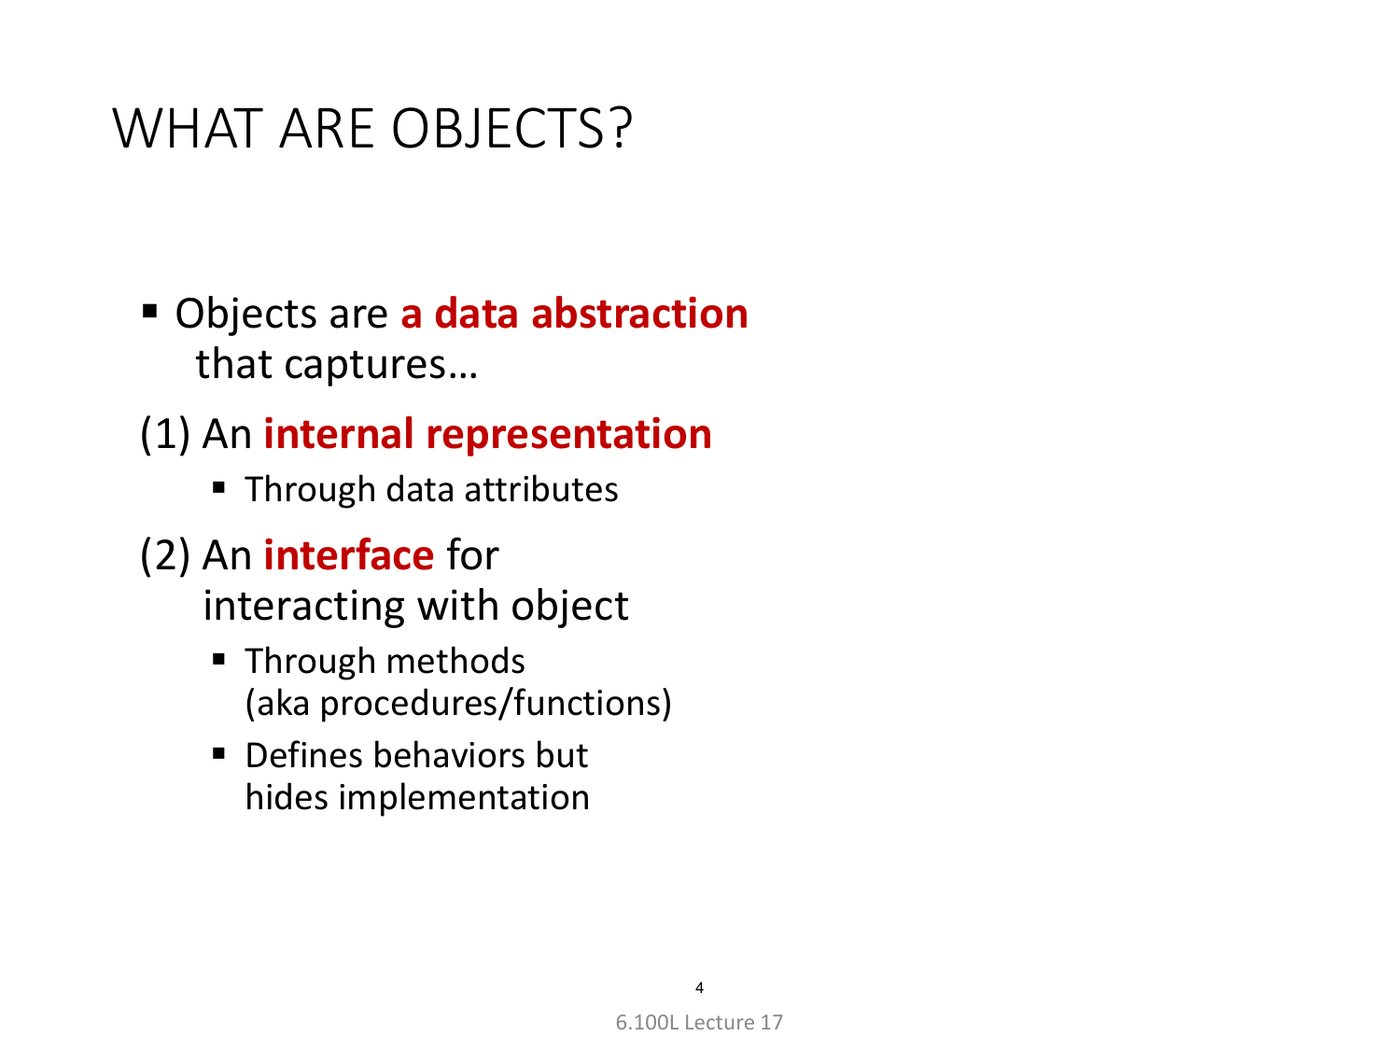

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 4 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

In short: an object = **data** + **things you can do with it**.

<br>

Python gives you lists, dictionaries and strings. A **class** lets you make your own kind of object. MIT's example is a point on a plane, `Coordinate`. Its data is an `x` and a `y`:

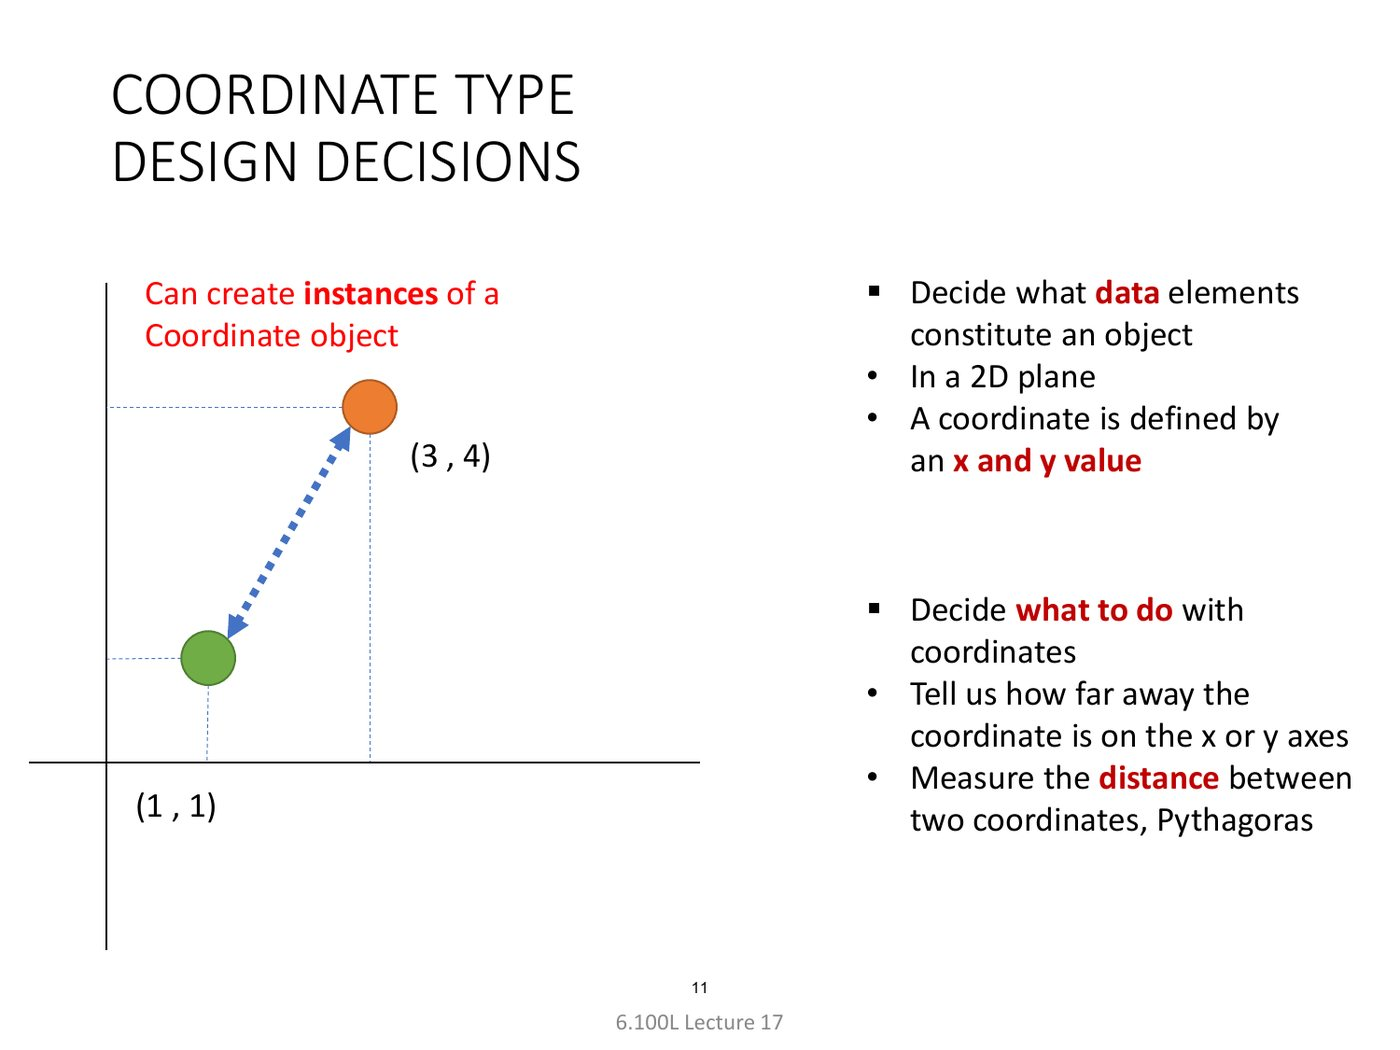

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 11 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

The smallest class has nothing inside. Calling it makes one object, called an **instance**:

In [ ]:
class Coordinate:
    pass

c = Coordinate()
print(type(c))

`c` is empty for now. You can save values on it with a dot, and read them back the same way:

In [ ]:
c.x = 3
c.y = 4
print(c.x, c.y)   # 3 4

A value saved on an object, like `c.x`, is called an **attribute**.

<br>

Your turn. Put these steps in a function, so one call makes a whole point.

### W1 · Make a point by hand

Write a function `make_point(x, y)` that makes a new point with the empty `Coordinate` class above, saves the two numbers on it, and returns it.

**Input**
- `x`, `y`: two integers

**Output**
- a new `Coordinate` object `p` with `p.x == x` and `p.y == y`

**Example 1**
```
Input:   p = make_point(3, 4)
         p.x, p.y
Output:  (3, 4)
```

**Example 2**
```
Input:   a = make_point(1, 2)
         b = make_point(5, 6)
         a.x, b.x
Output:  (1, 5)
```
`a` and `b` are two different points, so each keeps its own values.

**Constraints**
- Use the empty `class Coordinate:` from the cell above. Don't add anything to the class.
- The attribute names must be exactly `x` and `y`.
- Every call must make a **new** point.

In [ ]:
def make_point(x, y):
    # your code here
    pass


check("W1", make_point)

<details><summary>Hint</summary>

Three steps inside the function: make the point with `Coordinate()`, save `x` and `y` on it with a dot, then `return` it. Make the point **inside** the function, so each call gets a new one.

</details>
<details><summary>Solution</summary>

<pre>def make_point(x, y):
    p = Coordinate()
    p.x = x
    p.y = y
    return p</pre>

If the point were made once outside the function, every call would change and return that same point, so `a` and `b` would end up as one object.

</details>

<br>

`make_point` works, but every class would need its own `make_...` function. Python has a built-in way to do the same job: a method called `__init__`. It runs by itself right when the point is made:

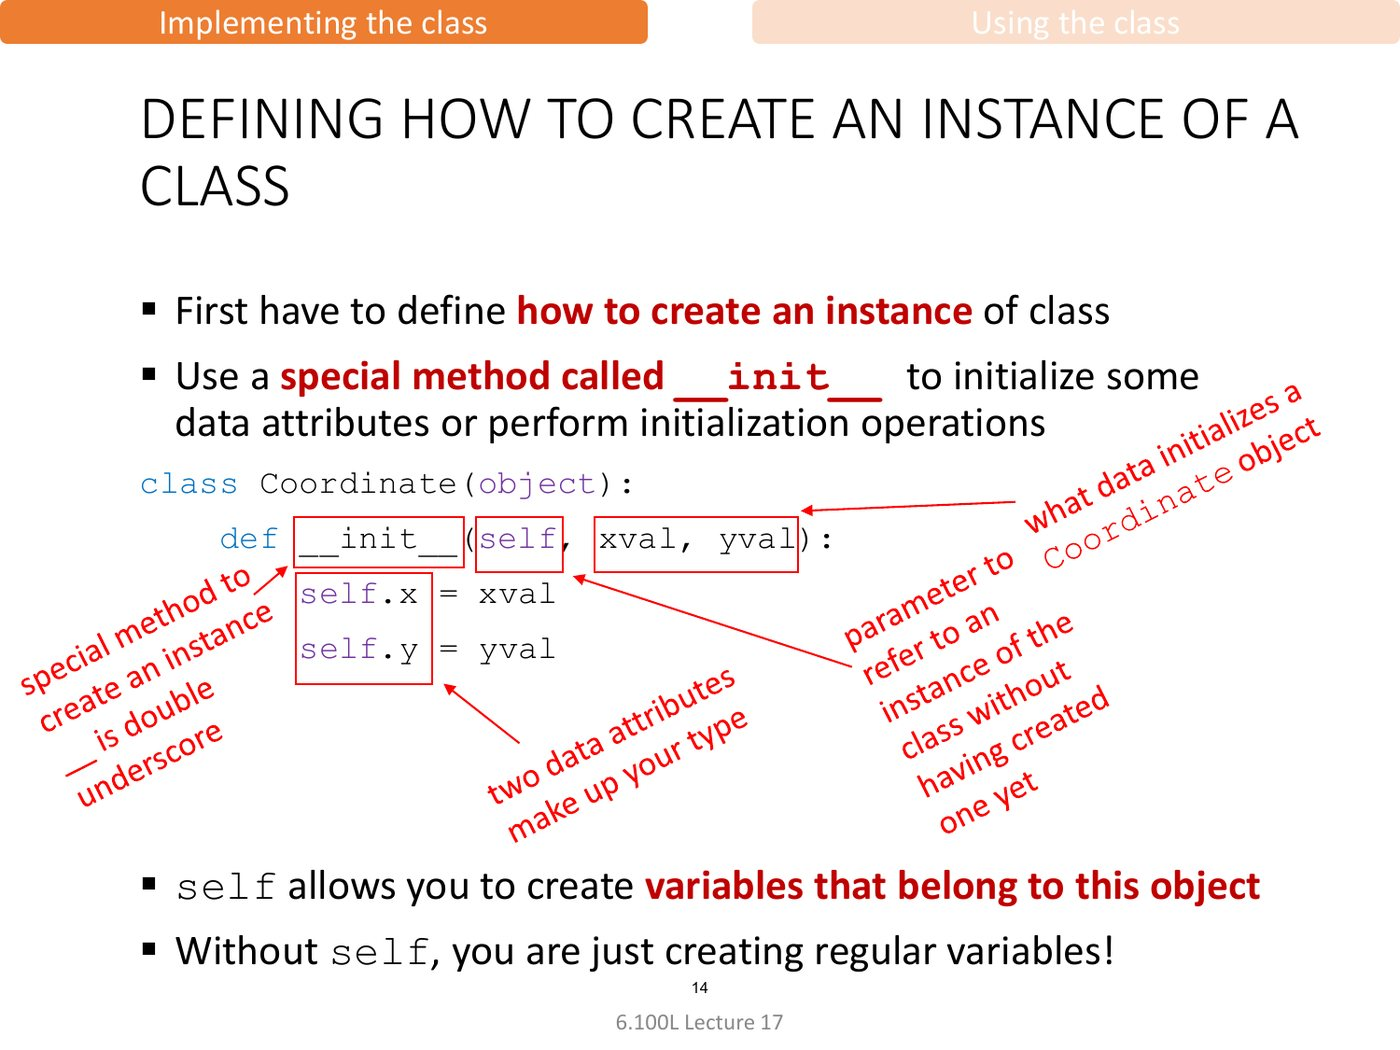

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 14 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

- `self` is the new point being made.
- `self.x = xval` does what `p.x = x` did in `make_point`, with `self` in place of `p`.

(The slide writes `class Coordinate(object):`. In Python 3, `class Coordinate:` means the same.)

MIT's picture for `self`: the class is the plan of a room, each room built from it is an instance, and `self` means "this room".

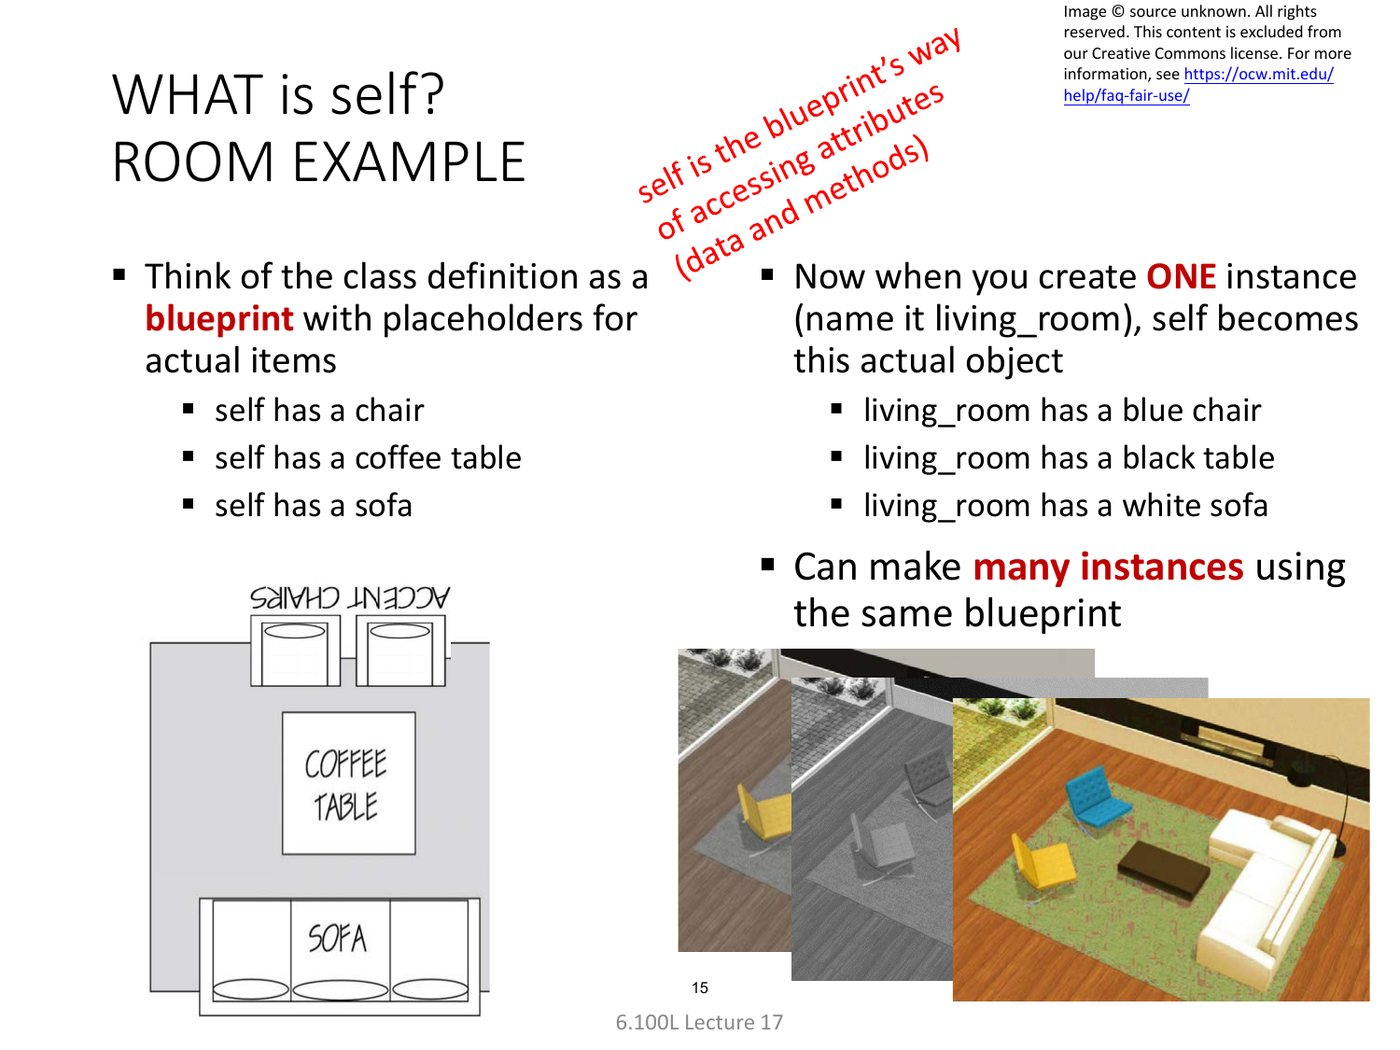

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 15 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0 (the room pictures on this slide are not covered by this license, as the note on the slide says)</sub>

Now the same class with `__init__`. Run it:

In [ ]:
class Coordinate:
    def __init__(self, xval, yval):
        self.x = xval
        self.y = yval

c = Coordinate(3, 4)
origin = Coordinate(0, 0)
print(c.x)        # 3
print(origin.x)   # 0

You pass two values, and Python fills in `self` by itself. Each instance keeps its own `x` and `y`:

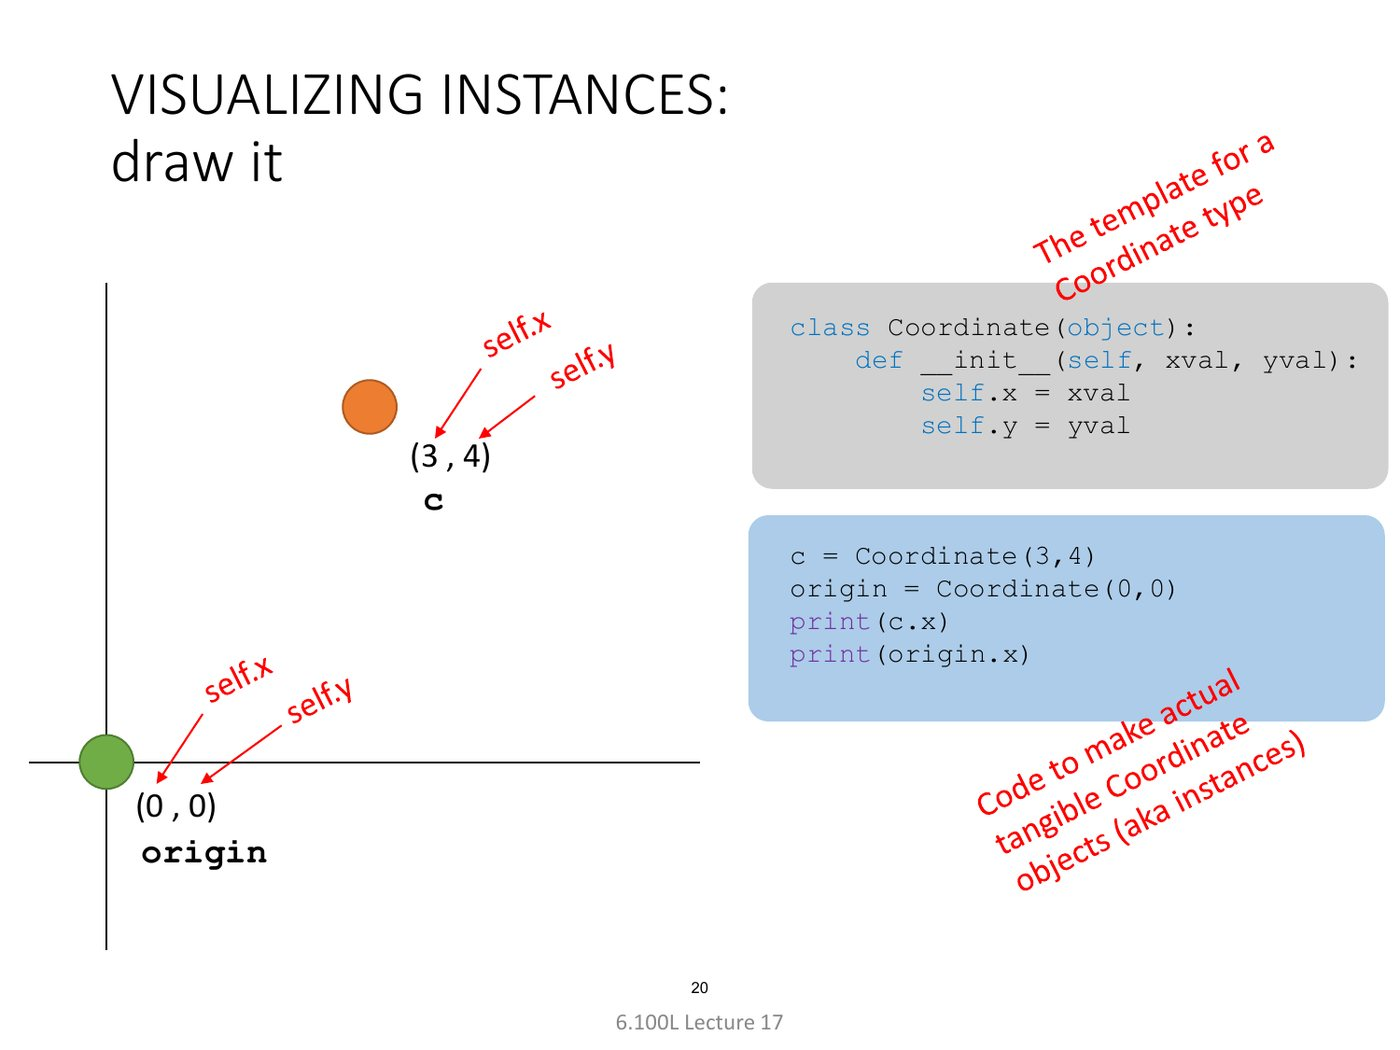

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 20 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

In [ ]:
#@title Q1 · Quick check { display-mode: "form" }
quiz('What does this program print?',
     ['3', '4', '5', '6'], 2,
     hint='d is its own instance. Its x is the first value passed to it, 5.',
     code='c = Coordinate(3, 4)\nd = Coordinate(5, 6)\nprint(d.x)',
     title='Q1')

<br>

Now your turn, with a student instead of a point. Same shape as `Coordinate`, with three values: a name and two test scores.

### W2 · Student

Write a class `Student` that stores one student's name and two test scores. Its `__init__` takes three values and saves each one on the object.

**Input**
- `Student(name, midterm, final)`
- `name`: a string, like `"Mina"`
- `midterm`, `final`: integers from 0 to 100

**Output**
- a `Student` object with three attributes: `name`, `midterm`, `final`

**Example 1**
```
Input:   s = Student("Mina", 85, 92)
         s.name, s.midterm, s.final
Output:  ('Mina', 85, 92)
```

**Example 2**
```
Input:   a = Student("Mina", 85, 92)
         b = Student("Jake", 78, 70)
         a.final, b.final
Output:  (92, 70)
```

**Constraints**
- The attribute names must be exactly `name`, `midterm` and `final`.
- Save the values as they are. Don't change them.

In [ ]:
class Student:
    def __init__(self, name, midterm, final):
        # your code here
        pass


check("W2", Student)

<details><summary>Hint</summary>

The same shape as `Coordinate`: one `self.something = something` line for each of the three values.

</details>
<details><summary>Solution</summary>

<pre>class Student:
    def __init__(self, name, midterm, final):
        self.name = name
        self.midterm = midterm
        self.final = final</pre>

`self.name = name`: on the left is the value saved on the object, on the right is the parameter. The parameter disappears when `__init__` ends; `self.name` stays on the student.

</details>

<br>

# 2 · Methods

So far a `Coordinate` only holds data. The things you can do with it are **methods**:

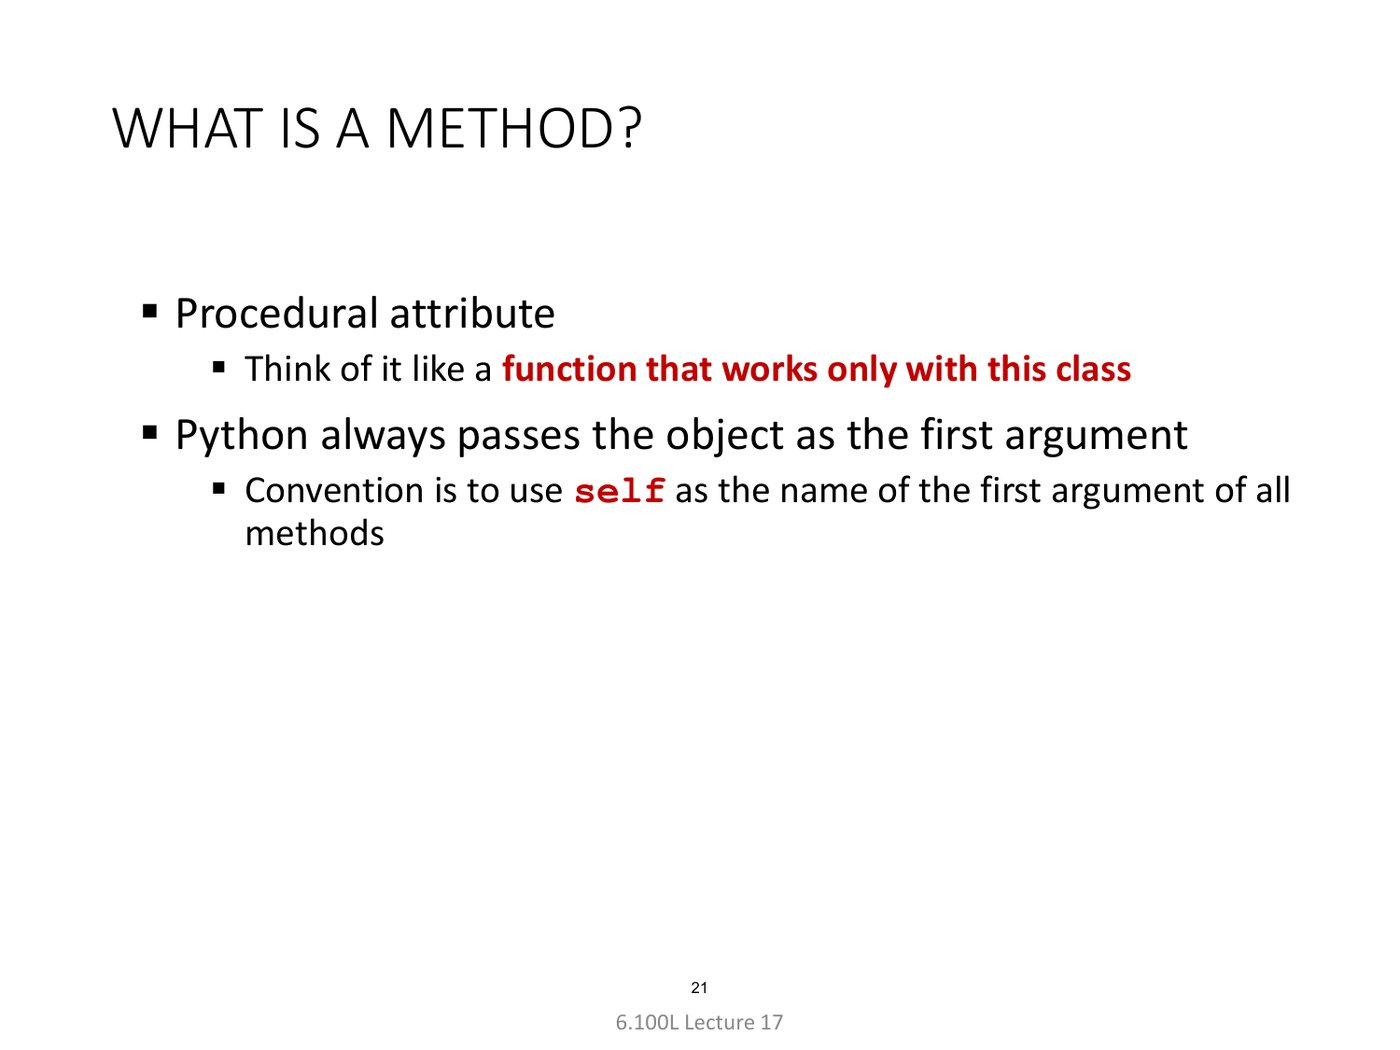

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 21 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

A method is a function inside the class. Its first parameter is always `self`. MIT's example measures the distance between two points:

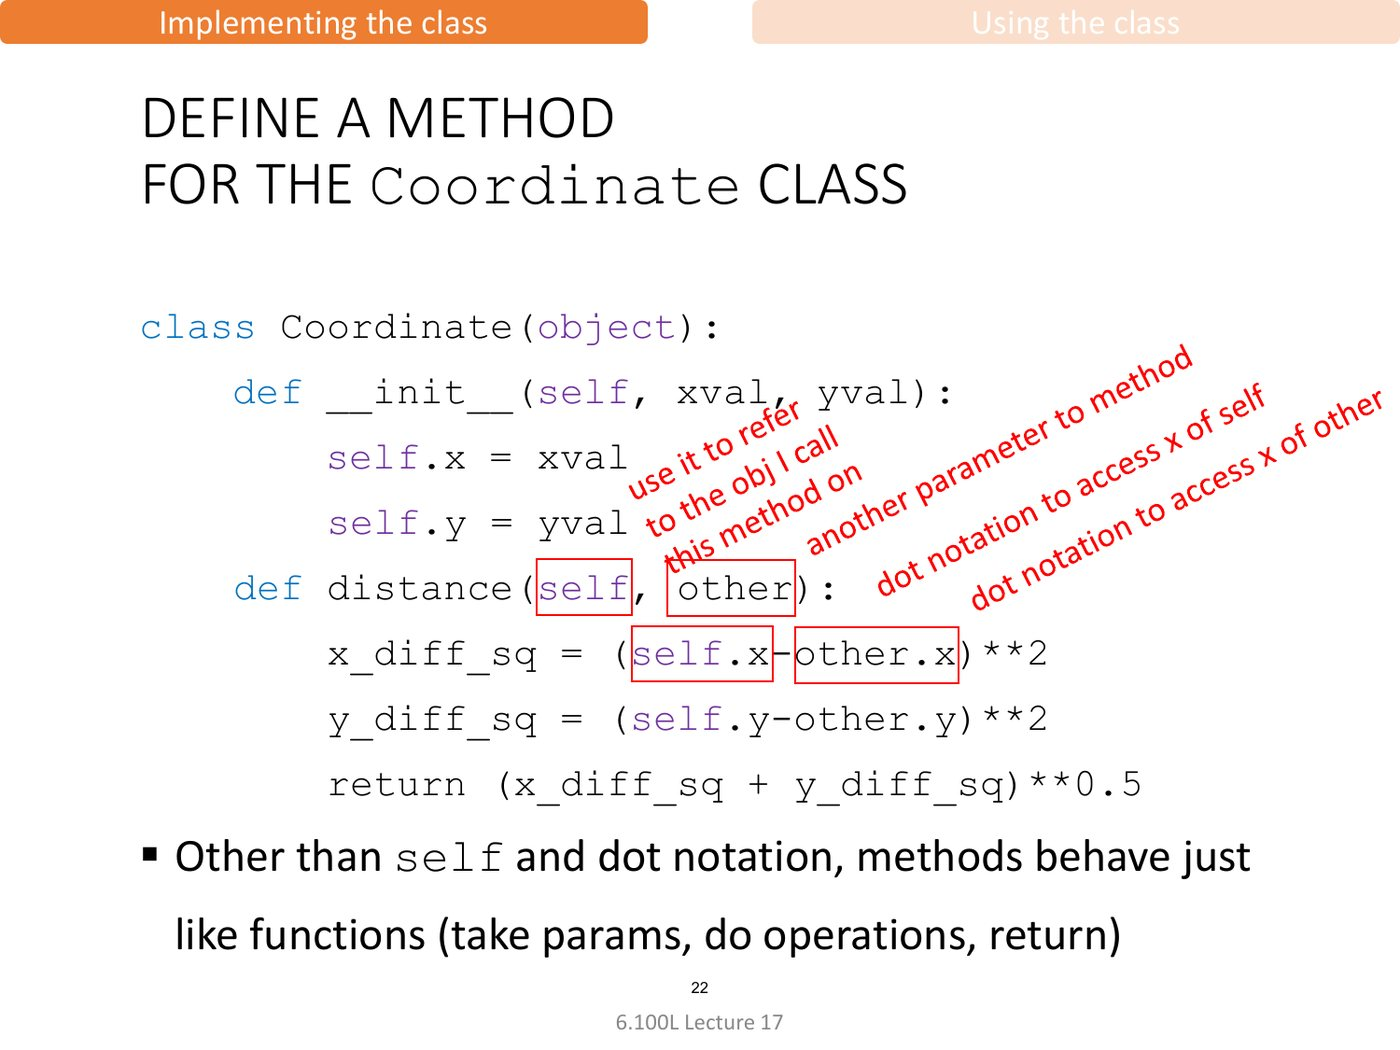

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 22 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

Run it. The class is the same as before, with `distance` added (marked `# new`):

In [ ]:
class Coordinate:
    def __init__(self, xval, yval):
        self.x = xval
        self.y = yval

    def distance(self, other):      # new
        x_diff_sq = (self.x - other.x) ** 2
        y_diff_sq = (self.y - other.y) ** 2
        return (x_diff_sq + y_diff_sq) ** 0.5

c = Coordinate(3, 4)
zero = Coordinate(0, 0)
print(c.distance(zero))   # 5.0

`c.distance(zero)` passes only `zero`, but `distance` has two parameters. Where does `self` come from?

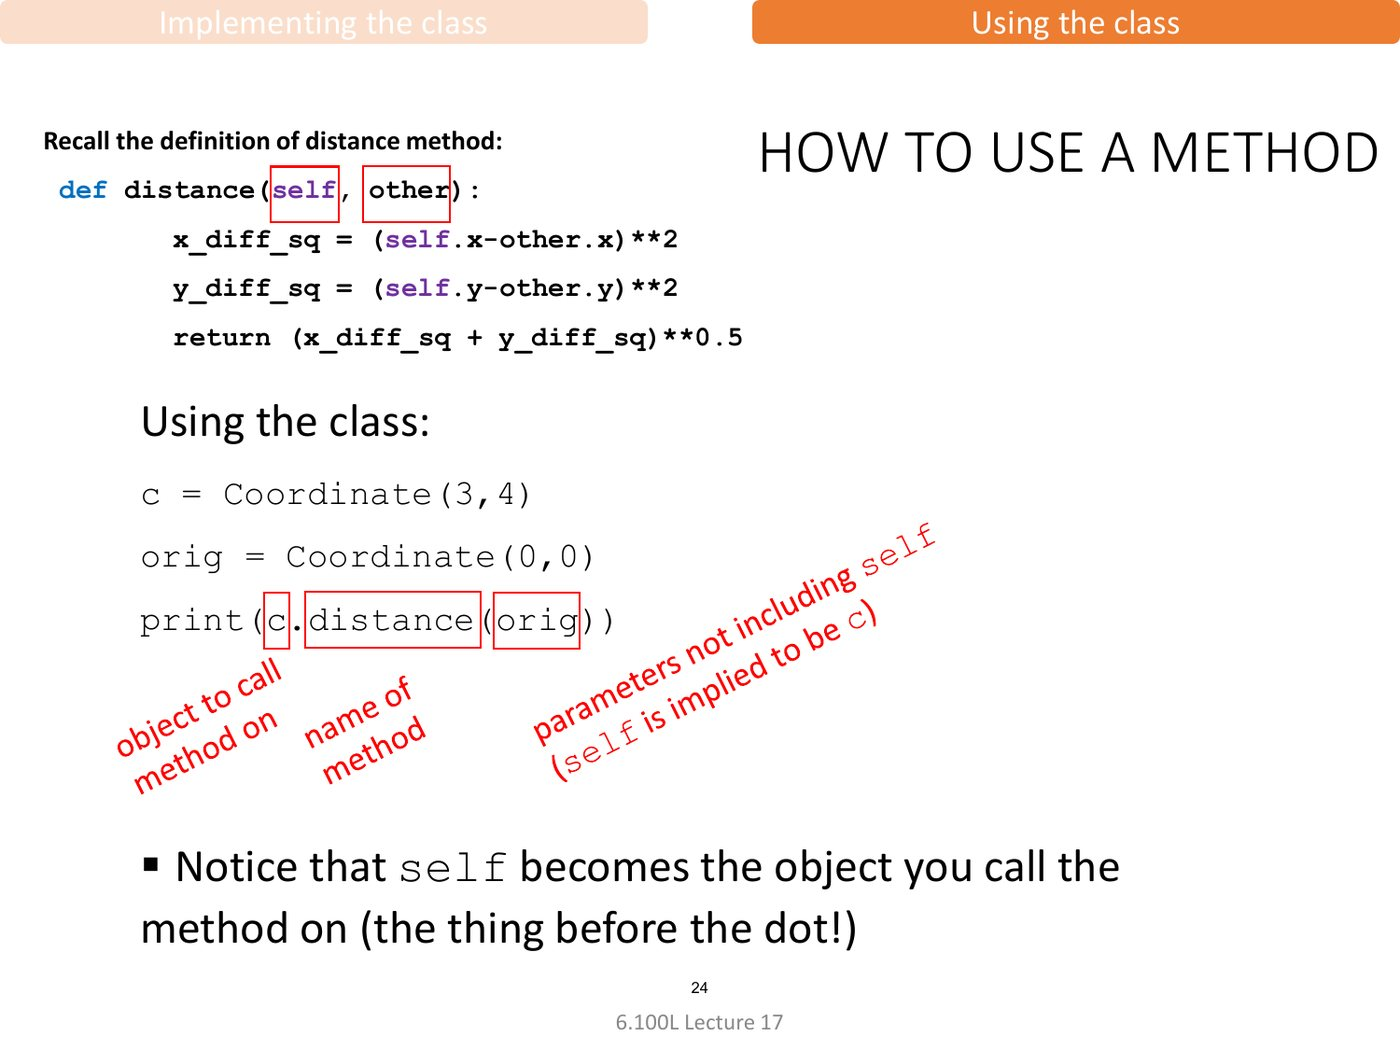

<sub>MIT 6.100L Fall 2022 · Lecture 17, slide 24 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

The object before the dot becomes `self`. (The slide calls the second point `orig`; here it is `zero`.)

In [ ]:
#@title Q2 · Quick check { display-mode: "form" }
quiz('to_origin is written without self. What happens on the last line?',
     ['c becomes (0, 0)', "NameError: name 'self' is not defined", 'TypeError: Coordinate.to_origin() takes 0 positional arguments but 1 was given', 'Nothing happens'], 2,
     hint='Python passes c in as the first argument. to_origin has no parameter to take it, so the call fails.',
     code='class Coordinate:\n    def __init__(self, xval, yval):\n        self.x = xval\n        self.y = yval\n\n    def to_origin():\n        self.x = 0\n        self.y = 0\n\nc = Coordinate(3, 4)\nc.to_origin()',
     title='Q2')

<br>

Your turn: give `Student` two methods, the same way `distance` reads `self.x`.

### W3 · average() and improved()

Add two methods to `Student`.

**Methods**
- `average()`: returns the average of `midterm` and `final`, as a number
- `improved()`: returns `True` if `final` is **higher** than `midterm`, otherwise `False`

**Example 1**
```
Input:   s = Student("Mina", 85, 92)
         s.average(), s.improved()
Output:  (88.5, True)
```

**Example 2**
```
Input:   s = Student("Jake", 78, 70)
         s.average(), s.improved()
Output:  (74.0, False)
```

**Example 3**
```
Input:   s = Student("Kai", 80, 80)
         s.improved()
Output:  False
```
The same score is not an improvement.

**Constraints**
- `return` the result. Don't `print` it.
- The methods must not change `midterm` or `final`.

In [ ]:
class Student:
    def __init__(self, name, midterm, final):
        self.name = name
        self.midterm = midterm
        self.final = final

    def average(self):
        # your code here
        pass

    def improved(self):
        # your code here
        pass


check("W3", Student)

<details><summary>Hint</summary>

Like `distance`, read the values through `self`: `self.midterm`, `self.final`. `improved` can return the comparison itself: `self.final > self.midterm`.

</details>
<details><summary>Solution</summary>

<pre>class Student:
    def __init__(self, name, midterm, final):
        self.name = name
        self.midterm = midterm
        self.final = final

    def average(self):
        return (self.midterm + self.final) / 2

    def improved(self):
        return self.final &gt; self.midterm</pre>

Each method only reads values that `__init__` already saved on `self`. Using `>` (not `>=`) is what makes Example 3 `False`.

</details>

<br>

# 3 · Printing an object

Try printing a coordinate:

In [ ]:
c = Coordinate(3, 4)
print(c)

Python doesn't know how to show it, so it shows a memory address. MIT fixes this with a special method:

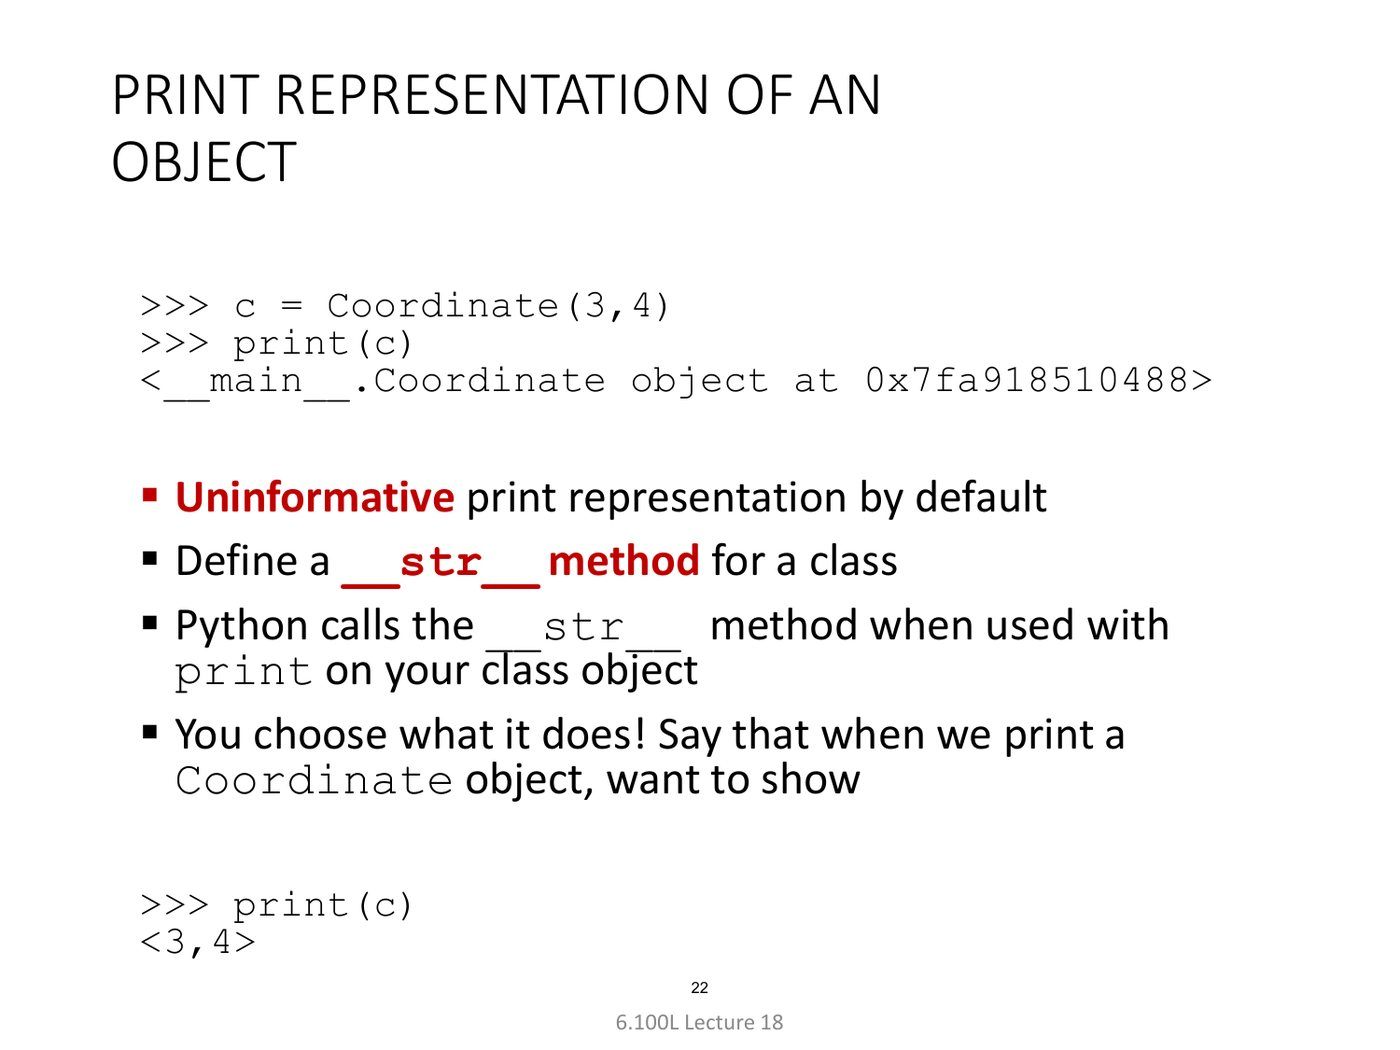

<sub>MIT 6.100L Fall 2022 · Lecture 18, slide 22 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

The slide uses `__str__`. We will use `__repr__` instead, because it works for `print` and also inside a list:

In [ ]:
class Coordinate:
    def __init__(self, xval, yval):
        self.x = xval
        self.y = yval

    def distance(self, other):
        x_diff_sq = (self.x - other.x) ** 2
        y_diff_sq = (self.y - other.y) ** 2
        return (x_diff_sq + y_diff_sq) ** 0.5

    def __repr__(self):                 # new
        return f"Coordinate({self.x}, {self.y})"

c = Coordinate(3, 4)
print(c)          # Coordinate(3, 4)
print([c, c])     # [Coordinate(3, 4), Coordinate(3, 4)]

<br>

Your turn. The name is a string, so it is shown in quotes.

### W4 · Student \_\_repr\_\_

Add `__repr__` to `Student`, so that a student shows like the line that creates it.

**Output**
- `__repr__` returns a string in exactly this form:
  `Student('<name>', <midterm>, <final>)`

**Example 1**
```
Input:   s = Student("Mina", 85, 92)
         print(s)
Output:  Student('Mina', 85, 92)
```

**Example 2**
```
Input:   print([Student("Mina", 85, 92), Student("Ava", 95, 97)])
Output:  [Student('Mina', 85, 92), Student('Ava', 95, 97)]
```

**Constraints**
- The name is in single quotes `'...'`. The scores are not in quotes.
- One comma and one space between the values.
- `return` the string. Don't `print` it.

In [ ]:
class Student:
    def __init__(self, name, midterm, final):
        self.name = name
        self.midterm = midterm
        self.final = final

    def average(self):
        return (self.midterm + self.final) / 2

    def improved(self):
        return self.final > self.midterm

    def __repr__(self):
        # your code here
        pass


check("W4", Student)

<details><summary>Hint</summary>

Build the string with an f-string, like `Coordinate`'s `__repr__`. Type the quotes around the name yourself: `'{self.name}'`.

</details>
<details><summary>Solution</summary>

<pre>class Student:
    def __init__(self, name, midterm, final):
        self.name = name
        self.midterm = midterm
        self.final = final

    def average(self):
        return (self.midterm + self.final) / 2

    def improved(self):
        return self.final &gt; self.midterm

    def __repr__(self):
        return f"Student('{self.name}', {self.midterm}, {self.final})"</pre>

The name is a string, so it is shown in quotes, the same way Python shows `'Mina'` in a list.

</details>

<br>

# 4 · From a file to objects

Real data comes in files. A common kind is **CSV**: plain text, one row per line, commas between the values, and the column names on the first line.

This cell makes a small CSV file of eight students. Just run it:

In [ ]:
csv_text = """name,midterm,final
Mina,85,92
Jake,78,70
Sora,90,88
Leo,62,75
Ava,95,97
Noah,70,65
Emma,88,80
Liam,55,68
"""

with open("students.csv", "w") as f:
    f.write(csv_text)

To read it, `csv.DictReader` turns each line into a dictionary, with the column names as keys:

In [ ]:
import csv

with open("students.csv") as f:
    for row in csv.DictReader(f):
        print(row)

`with open(...) as f:` opens the file as `f` and closes it when the block ends. Look at the output: every value is in quotes, the scores too. A CSV file is plain text, so everything comes back as a string.

In [ ]:
#@title Q3 · Quick check { display-mode: "form" }
quiz('What does  row["final"] - row["midterm"]  give?',
     ['7', "'7'", "TypeError: unsupported operand type(s) for -: 'str' and 'str'", "'9285'"], 2,
     hint='Both values are strings, and Python cannot subtract strings. Convert them first: int(row["final"]).',
     code='row = {"name": "Mina", "midterm": "85", "final": "92"}\nrow["final"] - row["midterm"]',
     title='Q3')

The whole path, from the file to `Student` objects:

<img src="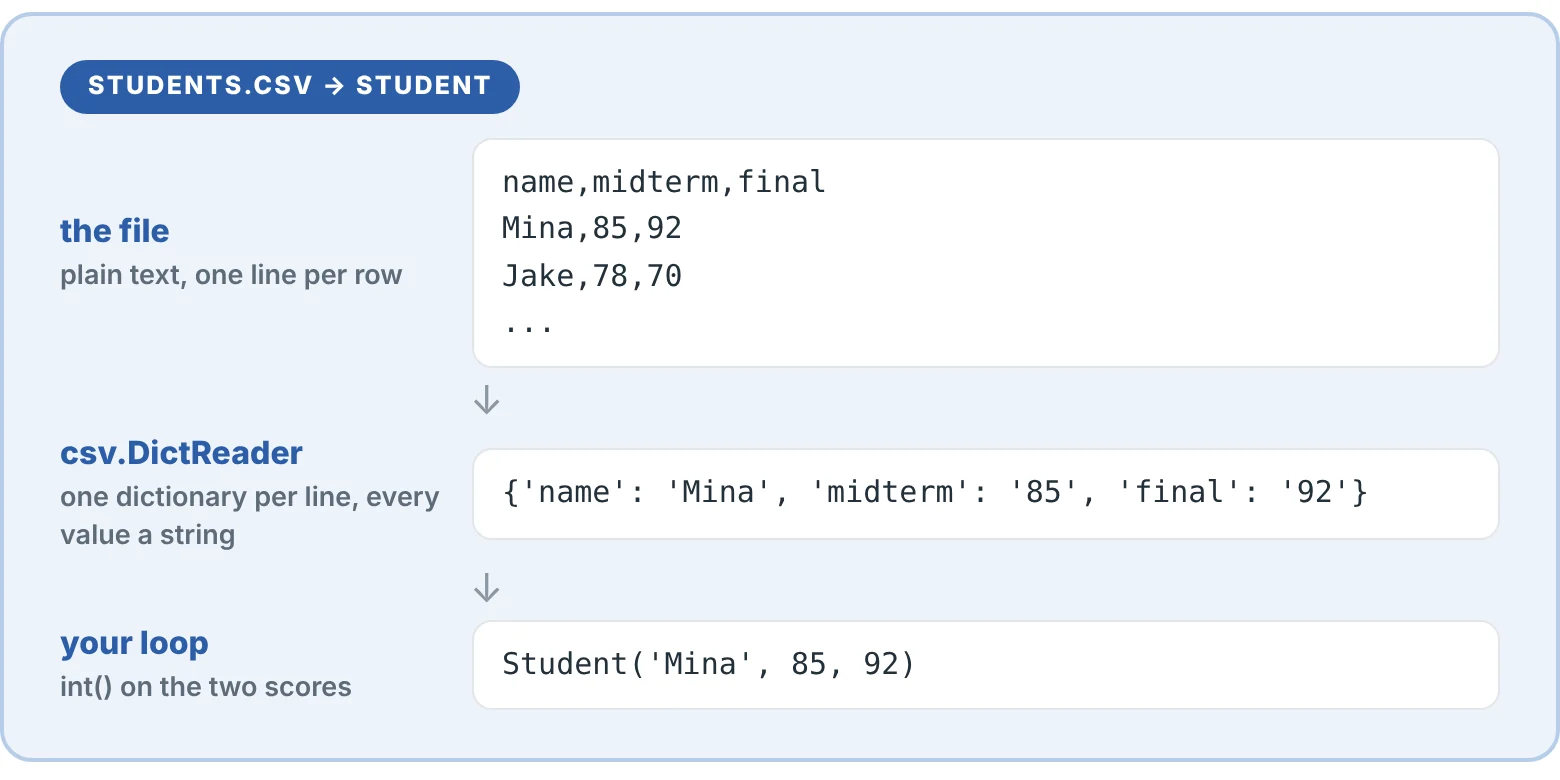" width="780" alt=".flow{display:flex;flex-direction:column;gap:6px}.step{display:grid;grid-template-columns:190px 1fr;gap:16px;align-items:center}.step .lab{font-weight:800;font-size:16px;color:#2c5ea8}.step .lab span{display:block;font-weight:600;font-size:13.5px;color:#5d6b78;margin-top:4px;line-height:1.4}.step pre{font-size:15px;padding:10px 14px;color:#22303a}.down{padding-left:205px;color:#8b98a3;font-size:20px;line-height:1}students.csv → Student the fileplain text, one line per row name,midterm,final Mina,85,92 Jake,78,70 ... ↓ csv.DictReaderone dictionary per line, every value a string {&#x27;name&#x27;: &#x27;Mina&#x27;, &#x27;midterm&#x27;: &#x27;85&#x27;, &#x27;final&#x27;: &#x27;92&#x27;} ↓ your loopint() on the two scores Student(&#x27;Mina&#x27;, 85, 92)">

So the loop needs one more step: `int()` on the two scores, then `Student(...)`:

In [ ]:
with open("students.csv") as f:
    for row in csv.DictReader(f):
        s = Student(row["name"], int(row["midterm"]), int(row["final"]))
        print(s.name, s.average())

<br>

P1 puts this loop in a function. Instead of printing, it collects the students in a list.

### P1 · Load students

Write `load_students(path)`: read a CSV file of students and return one `Student` per row.

**Input**
- `path`: the name of a CSV file. Its first line has the column names. It has the columns `name`, `midterm` and `final`, in any order, and it may have other columns too.

**Output**
- a list of `Student` objects, one per row, in the same order as the file
- `midterm` and `final` must be `int`s

**Example 1**
```
Input:   students = load_students("students.csv")
         len(students), students[0]
Output:  (8, Student('Mina', 85, 92))
```

**Example 2**
```
Input:   a file with these lines:
             final,name,class,midterm
             80,Emma,B,88
             100,Yuna,A,40
Output:  [Student('Emma', 88, 80), Student('Yuna', 40, 100)]
```
The columns are in another order, and there is an extra column `class`. Ignore it.

**Constraints**
- Read the values by column name, not by position.

In [ ]:
import csv

def load_students(path):
    # your code here
    pass


check("P1", load_students)

<details><summary>Hint</summary>

Start from the loop above. Make an empty list before the loop, `append` each `s` instead of printing it, and return the list at the end. `row["midterm"]` already reads by column name.

</details>
<details><summary>Solution</summary>

<pre>import csv

def load_students(path):
    students = []
    with open(path) as f:
        for row in csv.DictReader(f):
            s = Student(row["name"], int(row["midterm"]), int(row["final"]))
            students.append(s)
    return students</pre>

`csv.DictReader` gives each row as a dictionary with the column names as keys, so the order of the columns doesn't matter and extra columns are simply not used.

</details>

The last line of a cell also uses `__repr__`, so the list shows readably. (If this cell shows nothing or an error, finish P1 and W4 and run their cells again.)

In [ ]:
students = load_students("students.csv")
students

<br>

Now every item is a `Student`, so a loop can ask each one `s.improved()`:

### P2 · Who improved?

Write `improved_names(students)`: return the names of the students who improved.

**Input**
- `students`: a list of `Student` objects. It can be empty.

**Output**
- a list of the names of the students whose `improved()` is `True`, in the same order as the input

**Example 1**
```
Input:   improved_names(load_students("students.csv"))
Output:  ['Mina', 'Leo', 'Ava', 'Liam']
```

**Example 2**
```
Input:   improved_names([Student("A", 50, 60), Student("B", 60, 50), Student("C", 1, 2)])
Output:  ['A', 'C']
```

**Example 3**
```
Input:   improved_names([])
Output:  []
```

**Constraints**
- Each student already knows if they improved: call `s.improved()` from W3.

In [ ]:
def improved_names(students):
    # your code here
    pass


check("P2", improved_names)

<details><summary>Hint</summary>

The collect pattern: an empty list, a `for` loop with an `if`, and `append`. The `if` is just `s.improved()`.

</details>
<details><summary>Solution</summary>

<pre>def improved_names(students):
    names = []
    for s in students:
        if s.improved():
            names.append(s.name)
    return names</pre>

`improved_names` only asks each student `s.improved()`. How that is decided stays inside the class.

</details>

<br>

# 5 · A first look at pandas

Eight students is easy. Real data can have thousands of rows. From the next session you will use **pandas**, a library for tables. It is built from classes too, so the words from today come back right away:

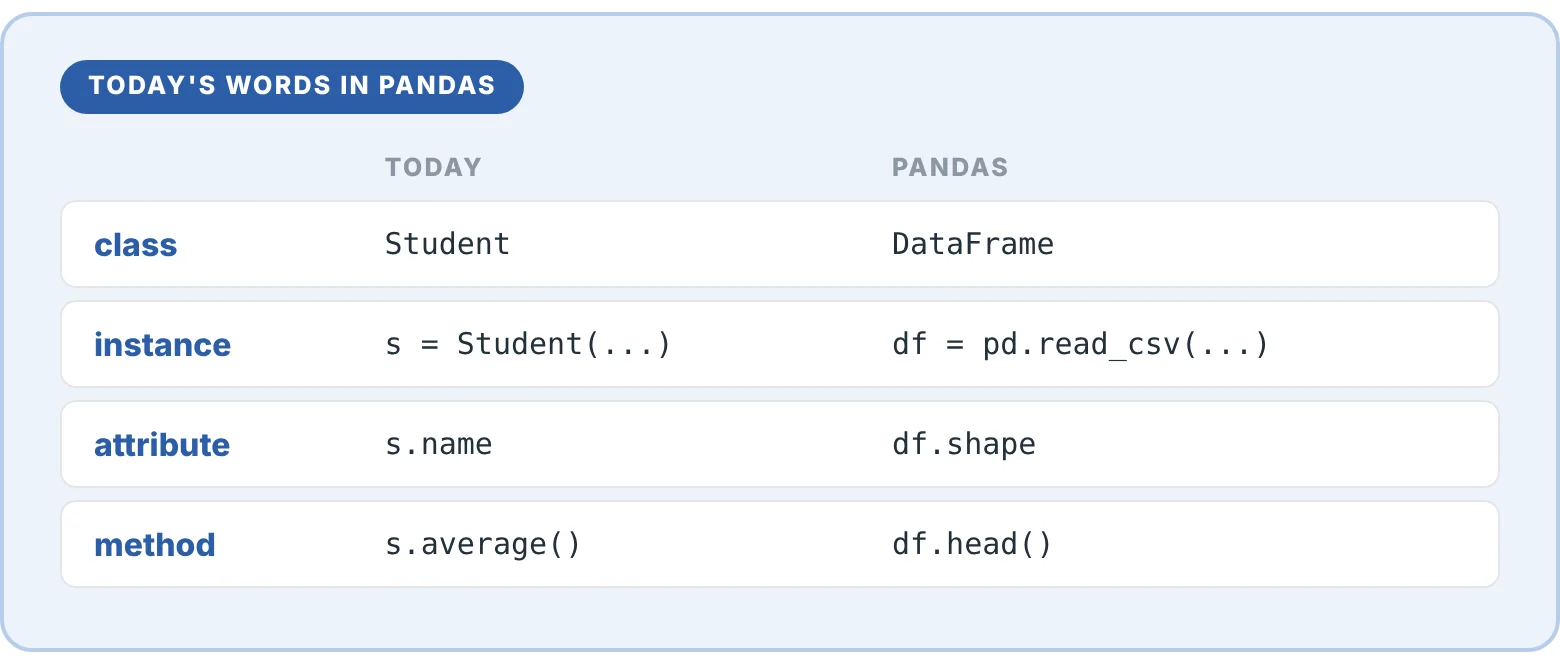

pandas reads a CSV file in one line:

In [ ]:
import pandas as pd

df = pd.read_csv("students.csv")
df

`df` is an instance of the class `DataFrame`. pandas draws a DataFrame like this:

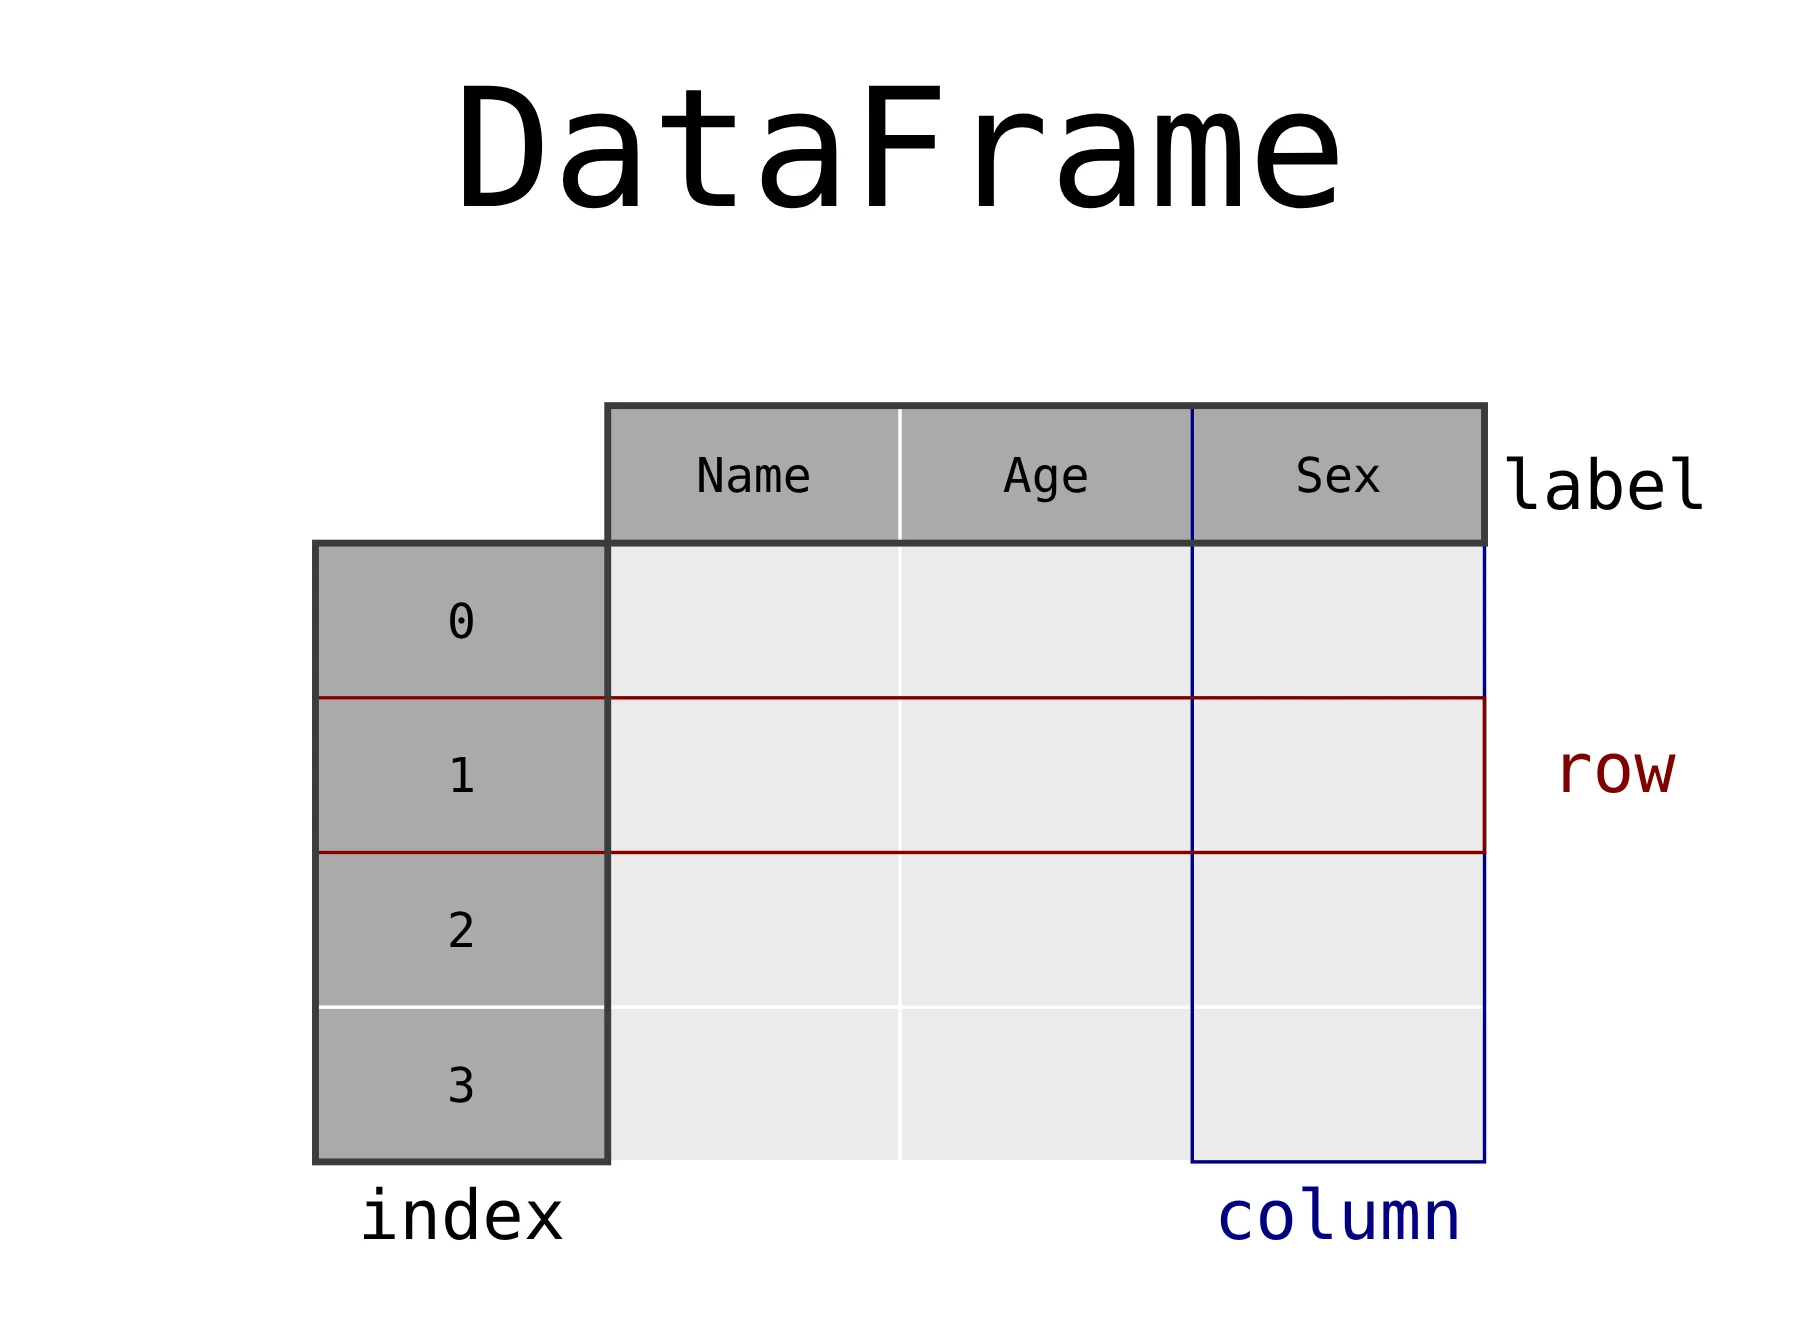

<sub>Image: pandas documentation, "Getting started" tutorials · BSD 3-Clause License</sub>

It works like your own objects: an attribute with a dot, a method with a dot and parentheses.

In [ ]:
print(df.shape)     # an attribute: (rows, columns)
df.head(3)          # a method: the first 3 rows

In [ ]:
#@title Q4 · Quick check { display-mode: "form" }
quiz('df.columns is written without parentheses. What is columns?',
     ['An attribute', 'A method', 'A class', 'A function'], 0,
     hint='No parentheses means a value saved on the object, like s.name. That is an attribute.',
     code='df.columns',
     title='Q4')

That is all for pandas today. You will use it properly from the next session.

<br>

# Recap

Why use classes at all? MIT's answer:

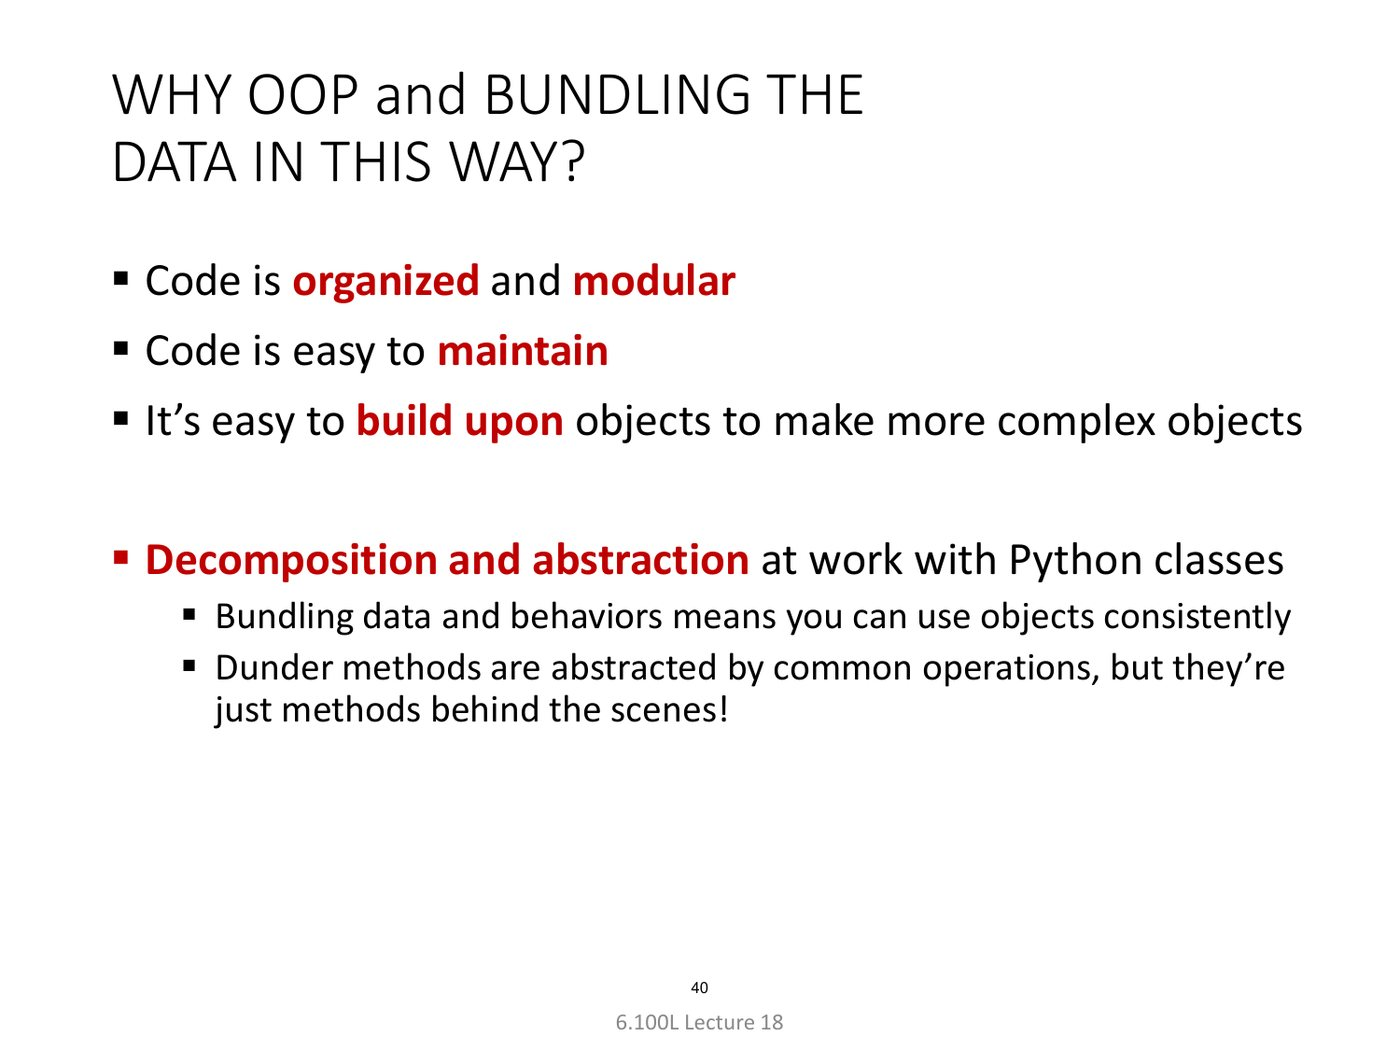

<sub>MIT 6.100L Fall 2022 · Lecture 18, slide 40 · Ana Bell · <a href="https://ocw.mit.edu/courses/6-100l-introduction-to-cs-and-programming-using-python-fall-2022/">OCW</a> · CC BY-NC-SA 4.0</sub>

"Dunder" means **d**ouble **under**score: methods like `__init__` and `__repr__`. You write them, and Python calls them for you.

Today in one line per section:

```python
s = Student("Mina", 85, 92)               # 1 · __init__ saves the values on s
s.average()                               # 2 · a method: self is s
print(s)                                  # 3 · uses __repr__
students = load_students("students.csv")  # 4 · one Student per row of the file
df = pd.read_csv("students.csv")          # 5 · pandas: also a class
```

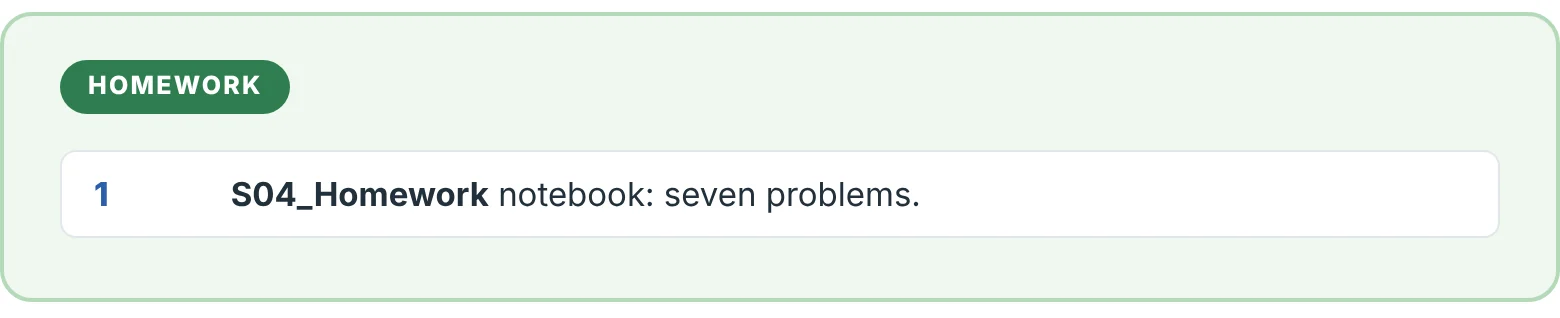

<br>

# Results

In [ ]:
#@title Show my results { display-mode: "form" }
show_results()